# 이미지 생성 : FashionMNIST

## 1. 데이터 소개

| 항목 | 내용 |
| --- | --- |
| 데이터 | `torchvision.datasets.FashionMNIST` |
| train / test | **60,000장 / 10,000장** |
| 이미지 | **28×28 흑백** |
| 클래스 | **10개** |

**클래스 이름표**

| 번호 | 클래스 | 번호 | 클래스 |
| --- | --- | --- | --- |
| 0 | T-shirt/top | 5 | Sandal |
| 1 | Trouser | 6 | Shirt |
| 2 | Pullover | 7 | Sneaker |
| 3 | Dress | 8 | Bag |
| 4 | Coat | 9 | Ankle boot |

## 2. 데이터 불러오기

**기존 코드로 데이터를 불러옵니다.**

> EDA 기준: 전처리 전 원본 이미지 `.data` / 픽셀값 **0~255**

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

# device 설정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 데이터셋 및 DataLoader 설정
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))  # [-1, 1] 범위로 정규화
])

train_dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader  = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)

# 클래스 이름 (FashionMNIST 클래스)
idx_to_class = {i: class_name for i, class_name in enumerate(train_dataset.classes)}
idx_to_class

{0: 'T-shirt/top',
 1: 'Trouser',
 2: 'Pullover',
 3: 'Dress',
 4: 'Coat',
 5: 'Sandal',
 6: 'Shirt',
 7: 'Sneaker',
 8: 'Bag',
 9: 'Ankle boot'}

## 3. EDA

**분석 흐름**

데이터 구조 → 클래스 분포 → 실제 이미지 → 픽셀 특성 → 이상·중복 검사

> 그래프 제목과 축은 글자 깨짐을 줄이기 위해 영어로 표시합니다.

### 3.1. EDA 준비

- **데이터 준비:** 원본 이미지와 레이블(이미지의 이름표)을 꺼냅니다.
- **재현성:** `SEED`를 고정해 다시 실행해도 같은 샘플을 뽑습니다.

In [2]:
import pandas as pd
from IPython.display import display

SEED = 42
class_names = train_dataset.classes
num_classes = len(class_names)

# .data에는 전처리 전 이미지, .targets에는 이미지의 이름표가 있어요.
train_images = train_dataset.data.cpu().numpy()
train_labels = train_dataset.targets.cpu().numpy()
test_images = test_dataset.data.cpu().numpy()
test_labels = test_dataset.targets.cpu().numpy()

datasets = {
    "train": (train_images, train_labels),
    "test": (test_images, test_labels),
}

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11})
print("EDA 준비 완료! 원본 이미지의 픽셀값을 사용합니다.")

EDA 준비 완료! 원본 이미지의 픽셀값을 사용합니다.


### 3.2. 이미지 데이터 구조 확인

#### 3.2.1. 데이터 개수, 저장 구조, 자료형 확인

**확인할 것:** 이미지와 레이블 개수가 같은지, 어떤 형태와 자료형으로 저장됐는지 확인합니다.

| 배열 형태 예시 | 뜻 |
| --- | --- |
| `(60000, 28, 28)` | 세로 28칸·가로 28칸인 이미지 **60,000장** |
| `(60000,)` | 이미지마다 붙은 이름표 **60,000개** |

In [3]:
structure_rows = []
for split, (images, labels) in datasets.items():
    structure_rows.append({
        "구분": split,
        "이미지 수": len(images),
        "레이블 수": len(labels),
        "개수 일치": len(images) == len(labels),
        "이미지 배열 형태": str(images.shape),
        "이미지 자료형": str(images.dtype),
        "레이블 배열 형태": str(labels.shape),
        "레이블 자료형": str(labels.dtype),
    })

print("데이터셋 종류:", type(train_dataset).__name__)
print("원본 이미지 저장 방식:", type(train_dataset.data).__name__)
print("원본 레이블 저장 방식:", type(train_dataset.targets).__name__)
display(pd.DataFrame(structure_rows))

데이터셋 종류: FashionMNIST
원본 이미지 저장 방식: Tensor
원본 레이블 저장 방식: Tensor


,구분,이미지 수,레이블 수,개수 일치,이미지 배열 형태,이미지 자료형,레이블 배열 형태,레이블 자료형
0,train,60000,60000,True,"(60000, 28, 28)",uint8,"(60000,)",int64
1,test,10000,10000,True,"(10000, 28, 28)",uint8,"(10000,)",int64


#### 3.2.2. 이미지 크기, 채널 수, 클래스 이름 확인

- **원본 한 장:** `(28, 28)` — 높이·너비
- **모델 입력 한 장:** `(1, 28, 28)` — 채널·높이·너비
- **채널 1개:** 색 대신 밝기를 담는 **흑백 이미지**입니다.

> 숫자 레이블과 실제 옷 이름의 연결도 함께 확인합니다.

In [4]:
size_rows = []
for split, dataset in {"train": train_dataset, "test": test_dataset}.items():
    image, label = dataset[0]
    size_rows.append({
        "구분": split,
        "원본 한 장 형태": str(tuple(dataset.data[0].shape)),
        "모델 입력 한 장 형태": str(tuple(image.shape)),
        "채널 수": image.shape[0],
        "높이": image.shape[1],
        "너비": image.shape[2],
        "모델 입력 자료형": str(image.dtype),
    })

display(pd.DataFrame(size_rows))
display(pd.DataFrame({"레이블 번호": range(num_classes), "클래스 이름": class_names}))

,구분,원본 한 장 형태,모델 입력 한 장 형태,채널 수,높이,너비,모델 입력 자료형
0,train,"(28, 28)","(1, 28, 28)",1,28,28,torch.float32
1,test,"(28, 28)","(1, 28, 28)",1,28,28,torch.float32


,레이블 번호,클래스 이름
0,0,T-shirt/top
1,1,Trouser
2,2,Pullover
3,3,Dress
4,4,Coat
5,5,Sandal
6,6,Shirt
7,7,Sneaker
8,8,Bag
9,9,Ankle boot


### 3.3. 클래스별 데이터 분포 확인

**목적:** 특정 클래스에 데이터가 몰려 있는지 확인합니다.

- **표:** train·test의 클래스별 개수와 비율
- **막대그래프:** 같은 그래프 안에서 막대 높이가 같으면 **클래스별 개수가 균등**

,레이블,클래스,train 개수,train 비율(%),test 개수,test 비율(%)
0,0,T-shirt/top,6000,10.0,1000,10.0
1,1,Trouser,6000,10.0,1000,10.0
2,2,Pullover,6000,10.0,1000,10.0
3,3,Dress,6000,10.0,1000,10.0
4,4,Coat,6000,10.0,1000,10.0
5,5,Sandal,6000,10.0,1000,10.0
6,6,Shirt,6000,10.0,1000,10.0
7,7,Sneaker,6000,10.0,1000,10.0
8,8,Bag,6000,10.0,1000,10.0
9,9,Ankle boot,6000,10.0,1000,10.0


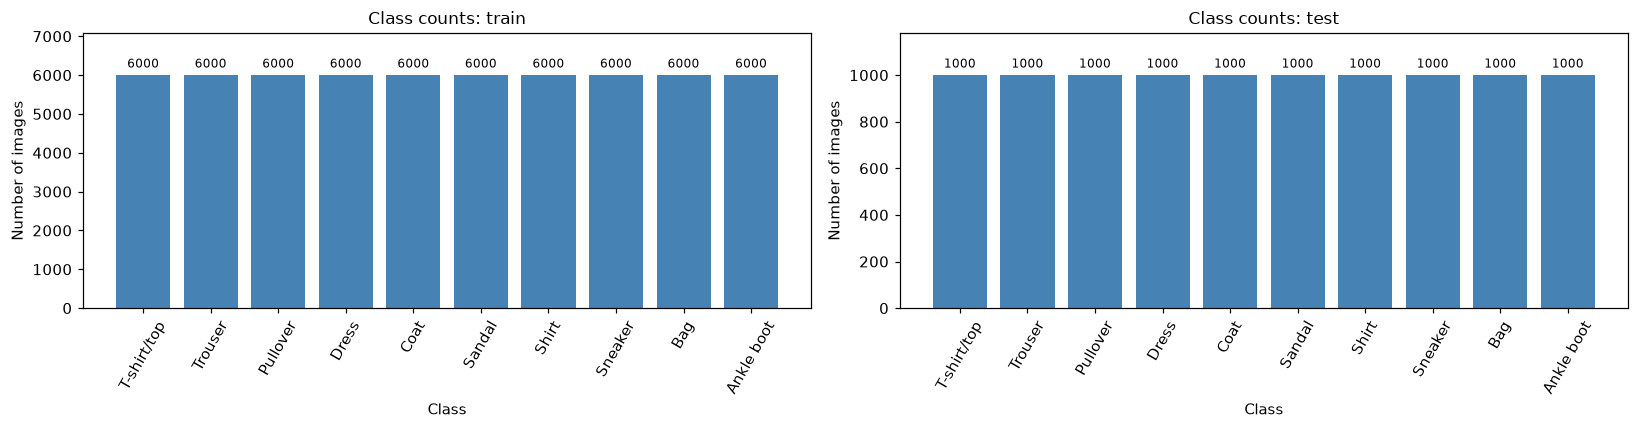

train: 모든 클래스가 6,000장씩으로 균등합니다.
test: 모든 클래스가 1,000장씩으로 균등합니다.


In [5]:
class_counts = {}
distribution = pd.DataFrame({"레이블": range(num_classes), "클래스": class_names})

for split, (images, labels) in datasets.items():
    counts = np.bincount(labels, minlength=num_classes)
    class_counts[split] = counts
    distribution[f"{split} 개수"] = counts
    distribution[f"{split} 비율(%)"] = (counts / len(labels) * 100).round(2)

display(distribution)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, split in zip(axes, datasets):
    bars = ax.bar(class_names, class_counts[split], color="steelblue")
    ax.bar_label(bars, padding=3, fontsize=8)
    ax.set(title=f"Class counts: {split}", xlabel="Class", ylabel="Number of images")
    ax.tick_params(axis="x", labelrotation=60)
    ax.set_ylim(0, class_counts[split].max() * 1.18)
plt.tight_layout()
plt.show()

for split, counts in class_counts.items():
    if counts.min() == counts.max():
        print(f"{split}: 모든 클래스가 {counts[0]:,}장씩으로 균등합니다.")
    else:
        print(f"{split}: 클래스별 개수가 다릅니다. 최소 {counts.min():,}장, 최대 {counts.max():,}장입니다.")

### 3.4. 클래스별 이미지 시각화

**train에서 클래스마다 무작위로 6장씩** 확인합니다.

**관찰 포인트:** 같은 클래스 안의 **모양 · 무늬 · 밝기 차이**

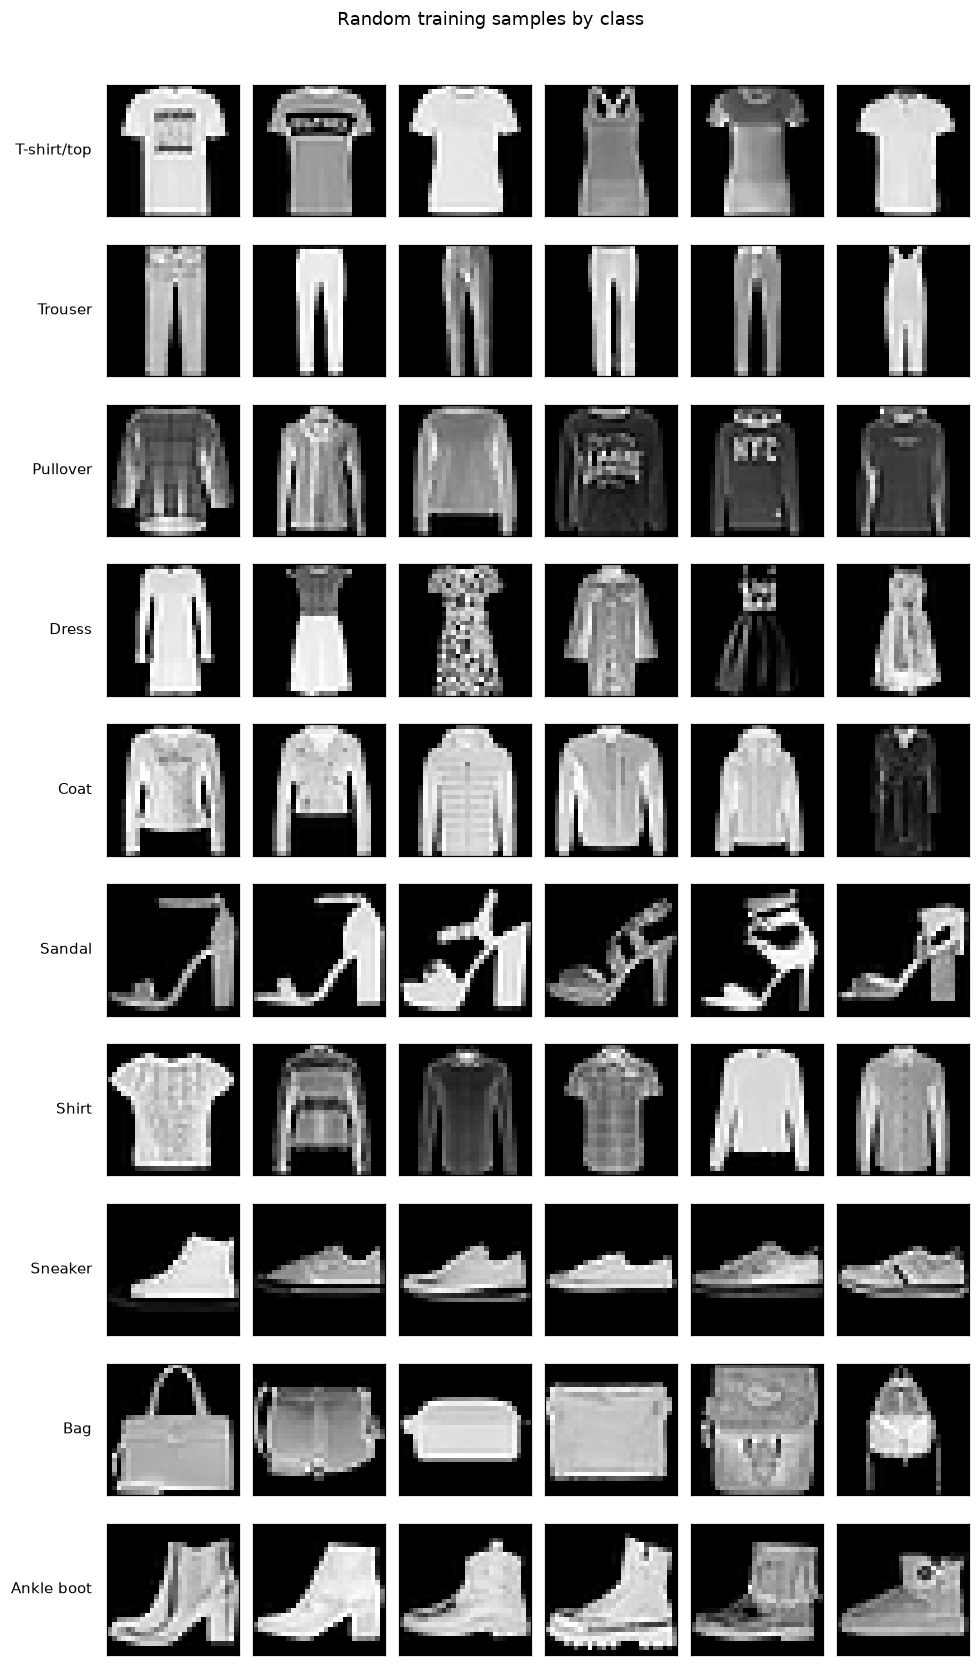

In [6]:
sample_rng = np.random.default_rng(SEED)
samples_per_class = 6
fig, axes = plt.subplots(num_classes, samples_per_class, figsize=(9, 15))

for label, name in enumerate(class_names):
    candidates = np.flatnonzero(train_labels == label)
    chosen = sample_rng.choice(candidates, size=min(samples_per_class, len(candidates)), replace=False)
    for column in range(samples_per_class):
        ax = axes[label, column]
        ax.set_xticks([])
        ax.set_yticks([])
        if column < len(chosen):
            ax.imshow(train_images[chosen[column]], cmap="gray", vmin=0, vmax=255)
        if column == 0:
            ax.set_ylabel(name, rotation=0, ha="right", va="center", labelpad=10)

fig.suptitle("Random training samples by class", y=1.01)
plt.tight_layout()
plt.show()

### 3.5. 클래스별 픽셀값 분석

#### 3.5.1. 픽셀값 분포 히스토그램

**픽셀:** 이미지를 이루는 작은 한 칸. **0은 검정, 255는 흰색**입니다.

- **가로축:** 픽셀의 밝기
- **세로축:** 해당 밝기 구간의 픽셀 비율

> train의 모든 픽셀을 사용하며, **검은 배경도 포함**합니다.

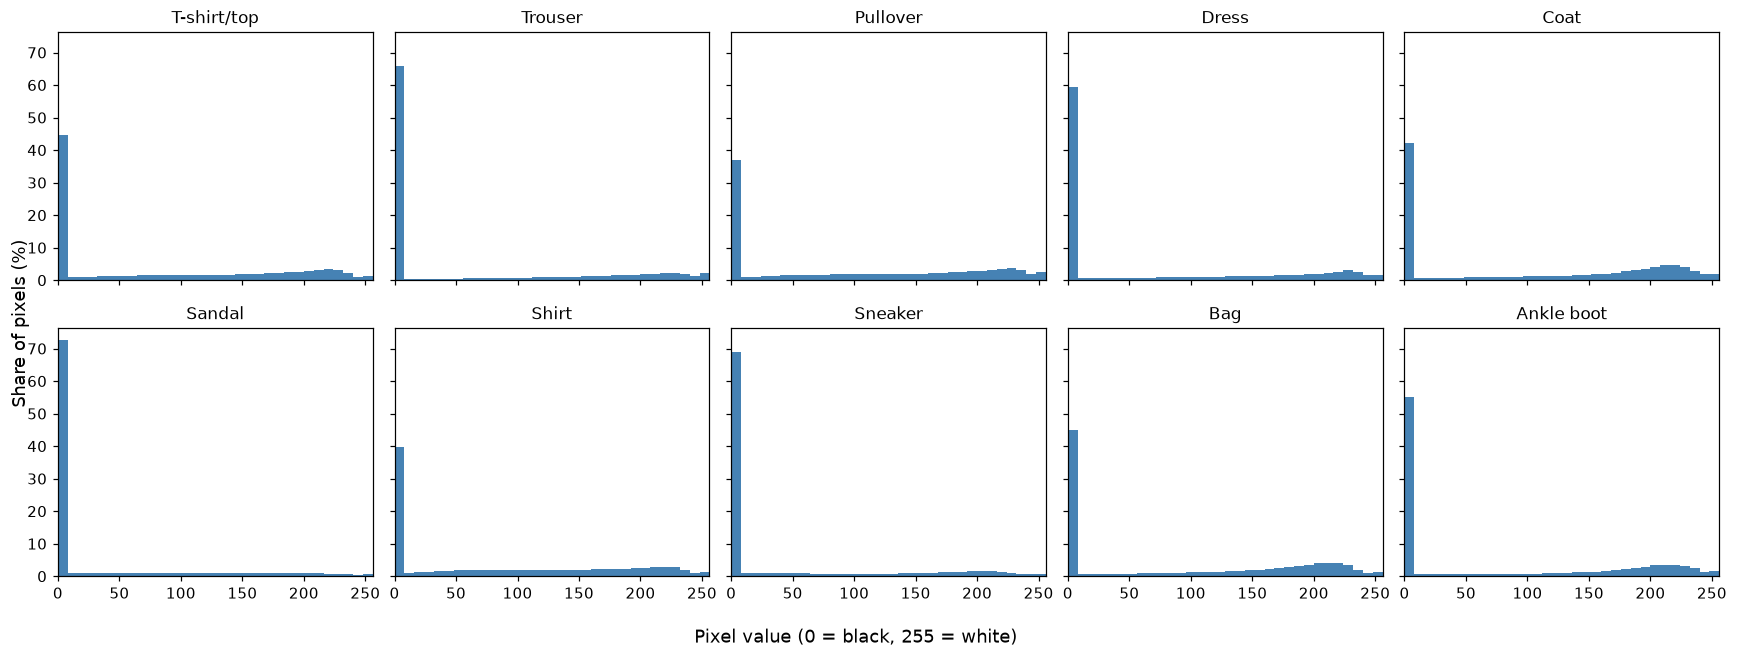

In [7]:
pixel_counts_by_class = []
mean_images = []
pixel_stat_rows = []

for label, name in enumerate(class_names):
    pixels = train_images[train_labels == label]
    pixel_counts_by_class.append(np.bincount(pixels.ravel(), minlength=256))
    mean_images.append(pixels.mean(axis=0))
    pixel_stat_rows.append({
        "클래스": name,
        "최솟값": int(pixels.min()),
        "최댓값": int(pixels.max()),
        "평균": float(pixels.mean()),
        "표준편차": float(pixels.std()),
    })

pixel_stats = pd.DataFrame(pixel_stat_rows)
fig, axes = plt.subplots(2, 5, figsize=(16, 6), sharex=True, sharey=True)

for label, ax in enumerate(axes.flat):
    counts = pixel_counts_by_class[label].reshape(32, 8).sum(axis=1)
    percentages = counts / counts.sum() * 100
    ax.bar(np.arange(0, 256, 8), percentages, width=8, align="edge", color="steelblue")
    ax.set(title=class_names[label], xlim=(0, 256))

fig.supxlabel("Pixel value (0 = black, 255 = white)")
fig.supylabel("Share of pixels (%)")
plt.tight_layout()
plt.show()

#### 3.5.2. 클래스별 평균 이미지·평균 히트맵·표준편차 히트맵

**열마다 같은 클래스**, 줄마다 다른 표시 방법입니다.

| 위치 | 보여주는 것 | 읽는 방법 |
| --- | --- | --- |
| **첫째 줄** | 평균 이미지 — 흑백 | 공통으로 나타나는 모양 |
| **둘째 줄** | 평균 히트맵 — 색 | 첫째 줄과 **같은 평균값**을 색으로 표시 |
| **셋째 줄** | 위치별 표준편차 히트맵 | 밝을수록 이미지마다 그 위치의 **밝기 차이가 큼** |

> train 원본 기준입니다. **같은 줄은 모든 클래스에 동일한 색 범위**를 적용합니다.

,클래스,최솟값,최댓값,평균,표준편차
0,T-shirt/top,0,255,83.03,89.44
1,Trouser,0,255,56.84,87.60
2,Pullover,0,255,96.06,91.46
3,Dress,0,255,66.02,90.33
4,Coat,0,255,98.26,95.96
5,Sandal,0,255,34.87,67.09
6,Shirt,0,255,84.61,86.52
7,Sneaker,0,255,42.76,75.17
8,Bag,0,255,90.16,93.14
9,Ankle boot,0,255,76.81,94.49


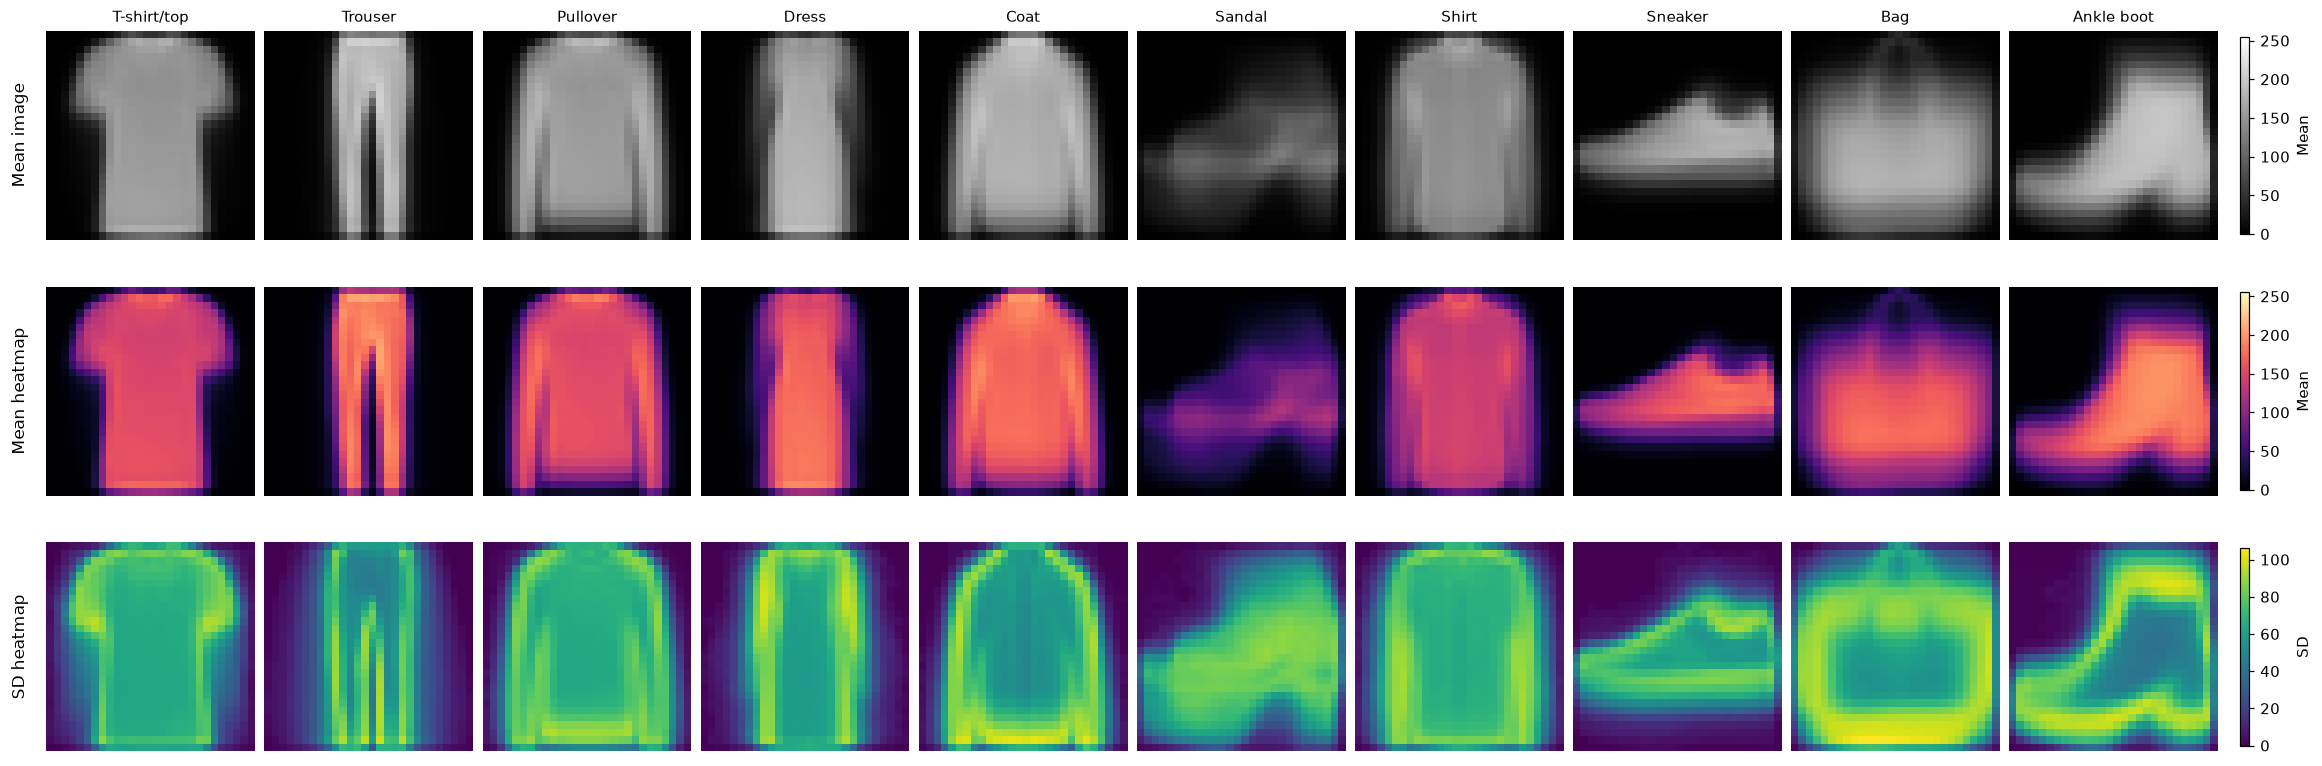

In [8]:
display(pixel_stats.round(2))

# 같은 클래스의 이미지를 위치별로 평균 내고 표준편차를 계산합니다.
heatmap_images = train_dataset.data.cpu().numpy()
heatmap_labels = train_dataset.targets.cpu().numpy()
heatmap_class_names = train_dataset.classes
mean_pixel_maps = []
std_pixel_maps = []

for label, name in enumerate(heatmap_class_names):
    class_images = heatmap_images[heatmap_labels == label]
    mean_pixel_maps.append(class_images.mean(axis=0))
    std_pixel_maps.append(class_images.std(axis=0, ddof=0))

std_color_max = max(float(pixel_map.max()) for pixel_map in std_pixel_maps)
std_color_max = max(std_color_max, 1.0)

# 열은 클래스, 행은 시각화 종류입니다.
fig, axes = plt.subplots(3, len(heatmap_class_names), figsize=(21, 7),
                         layout="constrained", squeeze=False)

for label, name in enumerate(heatmap_class_names):
    mean_image = axes[0, label].imshow(mean_pixel_maps[label], cmap="gray", vmin=0, vmax=255)
    mean_heatmap = axes[1, label].imshow(mean_pixel_maps[label], cmap="magma", vmin=0, vmax=255)
    std_heatmap = axes[2, label].imshow(std_pixel_maps[label], cmap="viridis", vmin=0, vmax=std_color_max)
    axes[0, label].set_title(name, fontsize=10)
    for row in range(3):
        ax = axes[row, label]
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

for row, label in enumerate(["Mean image", "Mean heatmap", "SD heatmap"]):
    axes[row, 0].set_ylabel(label, fontsize=11, labelpad=12)

fig.colorbar(mean_image, ax=axes[0, :].tolist(), shrink=0.8, pad=0.01, label="Mean")
fig.colorbar(mean_heatmap, ax=axes[1, :].tolist(), shrink=0.8, pad=0.01, label="Mean")
fig.colorbar(std_heatmap, ax=axes[2, :].tolist(), shrink=0.8, pad=0.01, label="SD")
plt.show()

#### 3.5.3. 검은 부분이 적은 이미지와 많은 이미지

**정렬 기준:** 이미지에서 **픽셀값이 정확히 0인 칸의 비율**

| 위치 | 클래스별 출력 |
| --- | --- |
| **윗줄** | 검정 비율이 **낮은 순 6장** |
| **아랫줄** | 검정 비율이 **높은 순 6장** |

> 어두운 회색은 제외합니다. 검은색 옷도 포함되므로 **검정 비율 = 배경 면적**은 아닙니다.

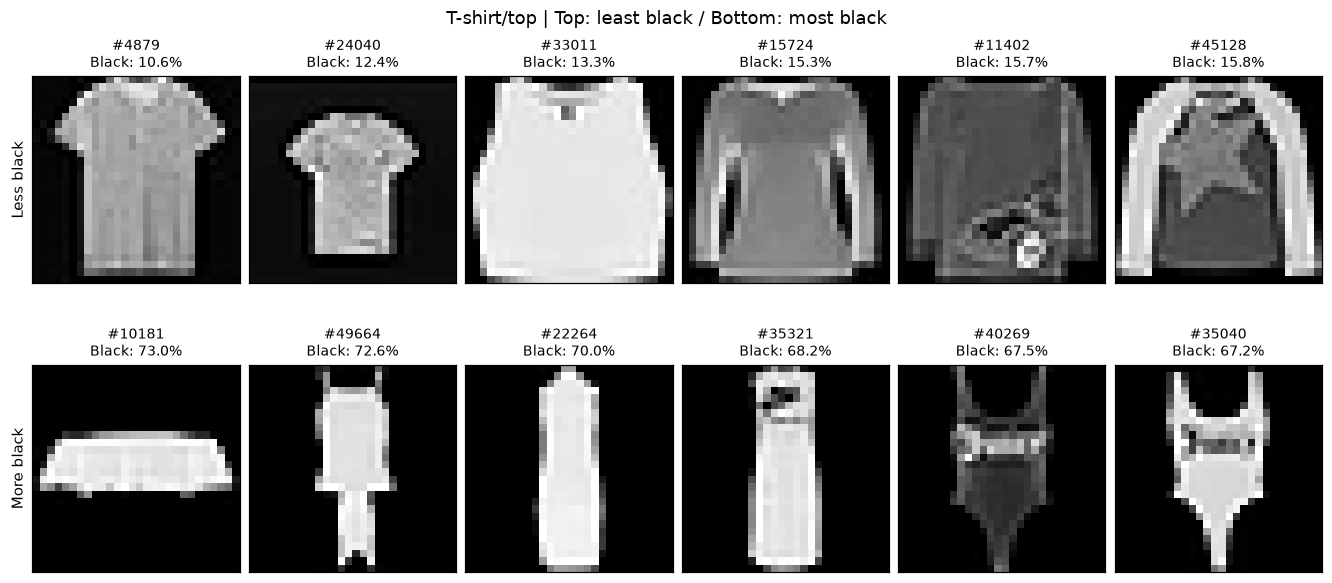

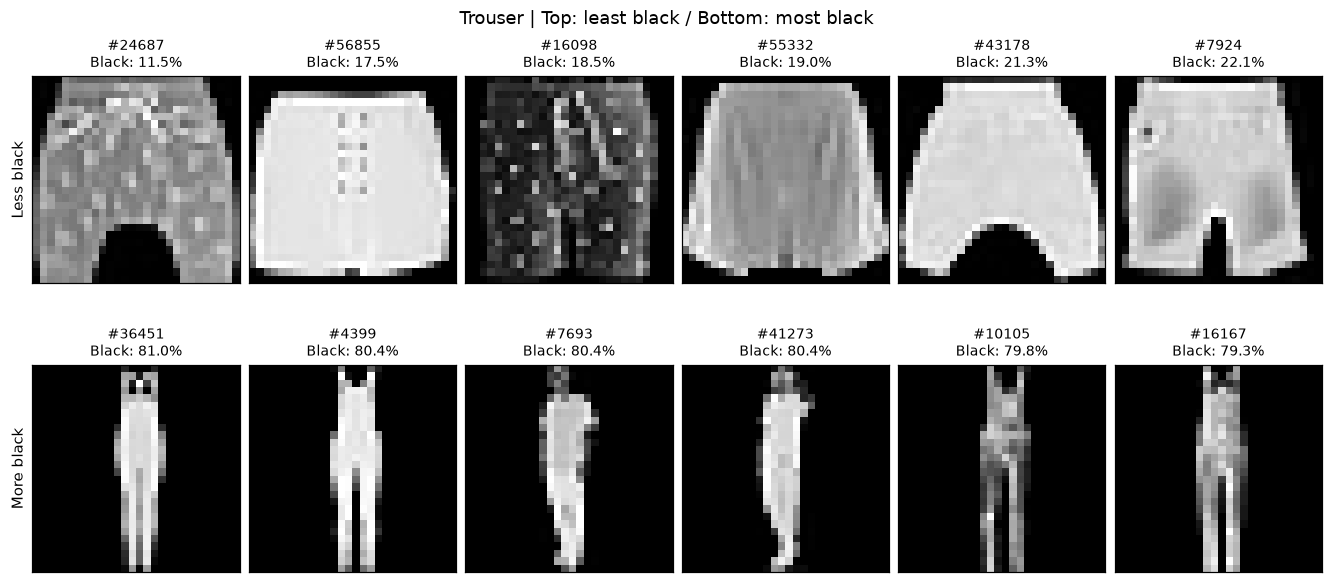

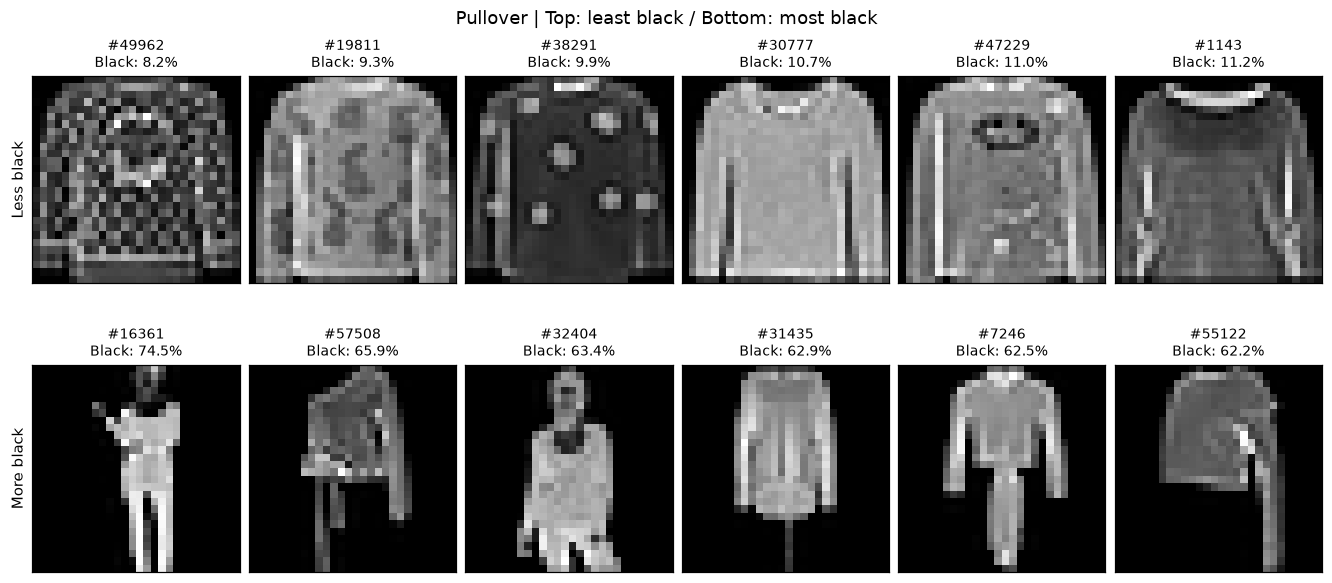

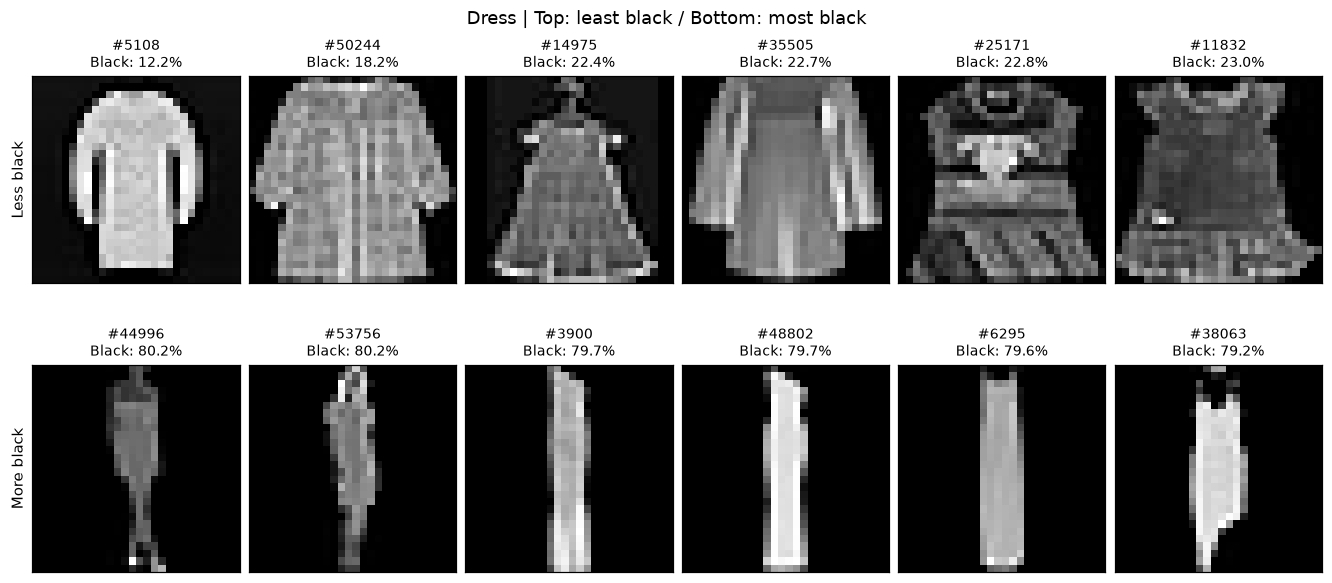

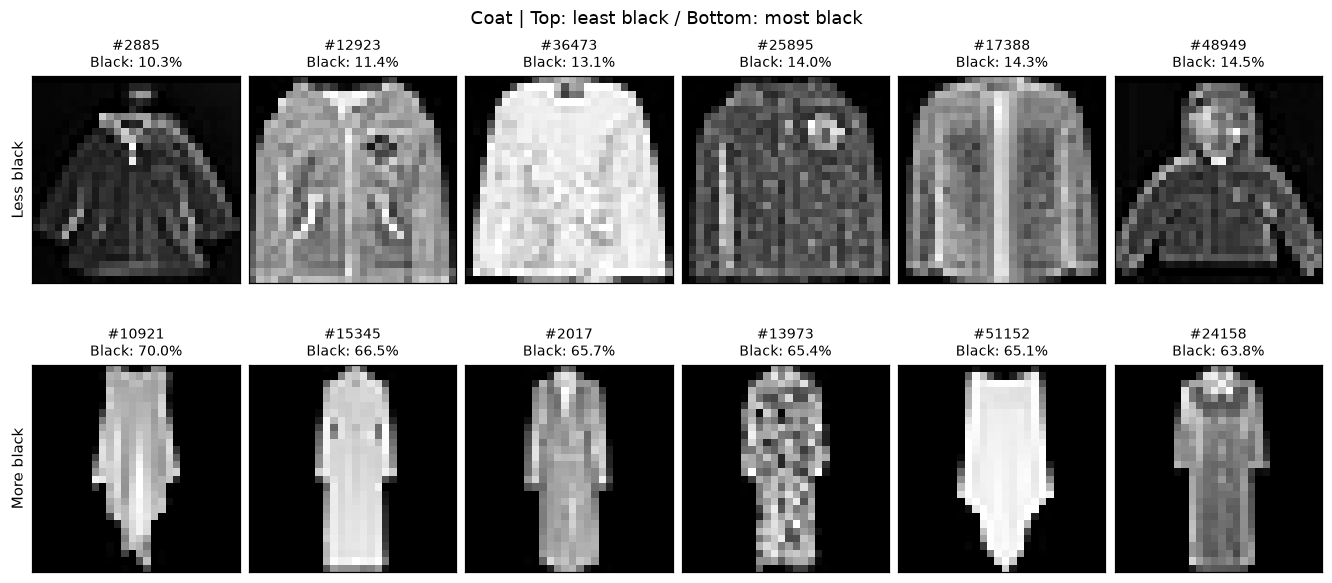

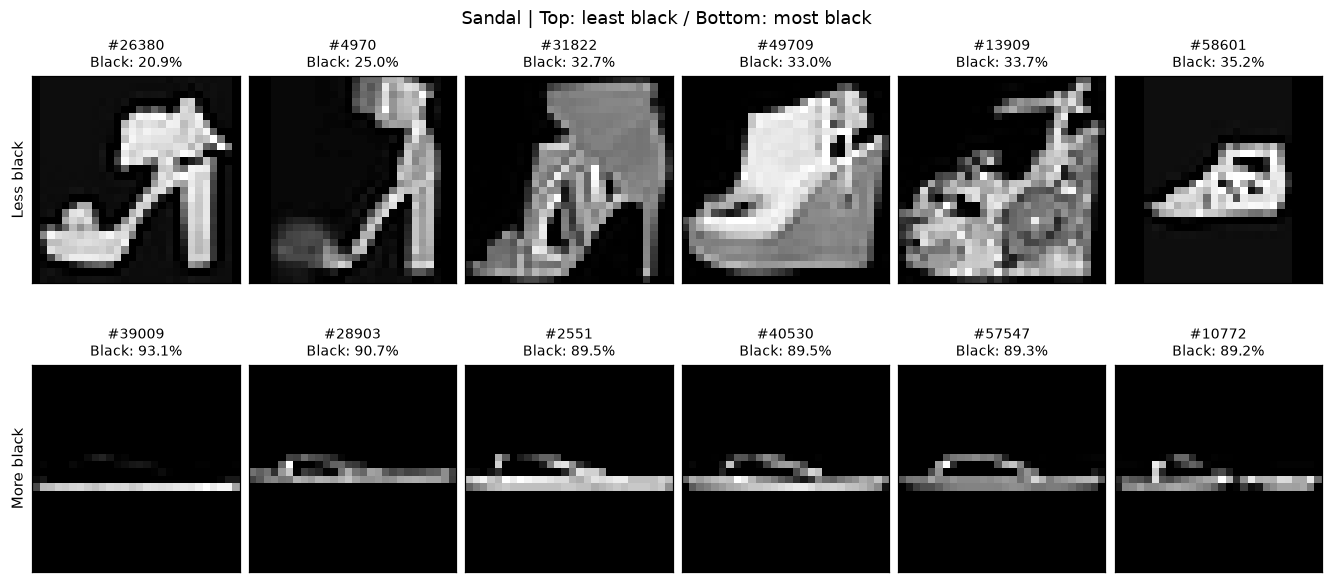

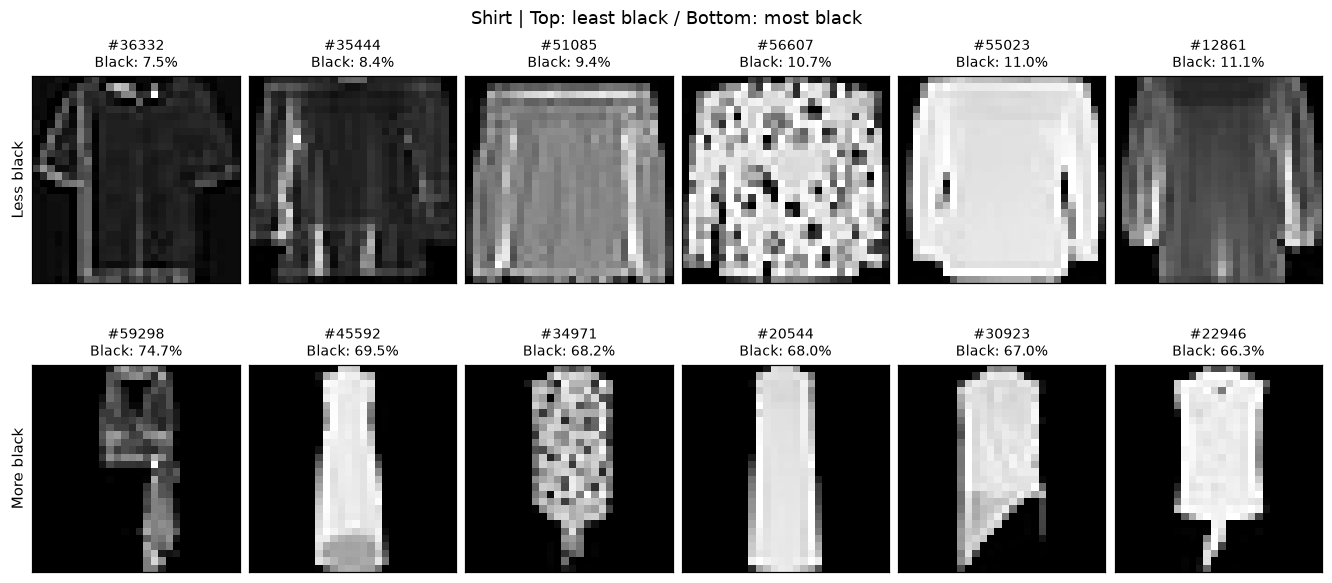

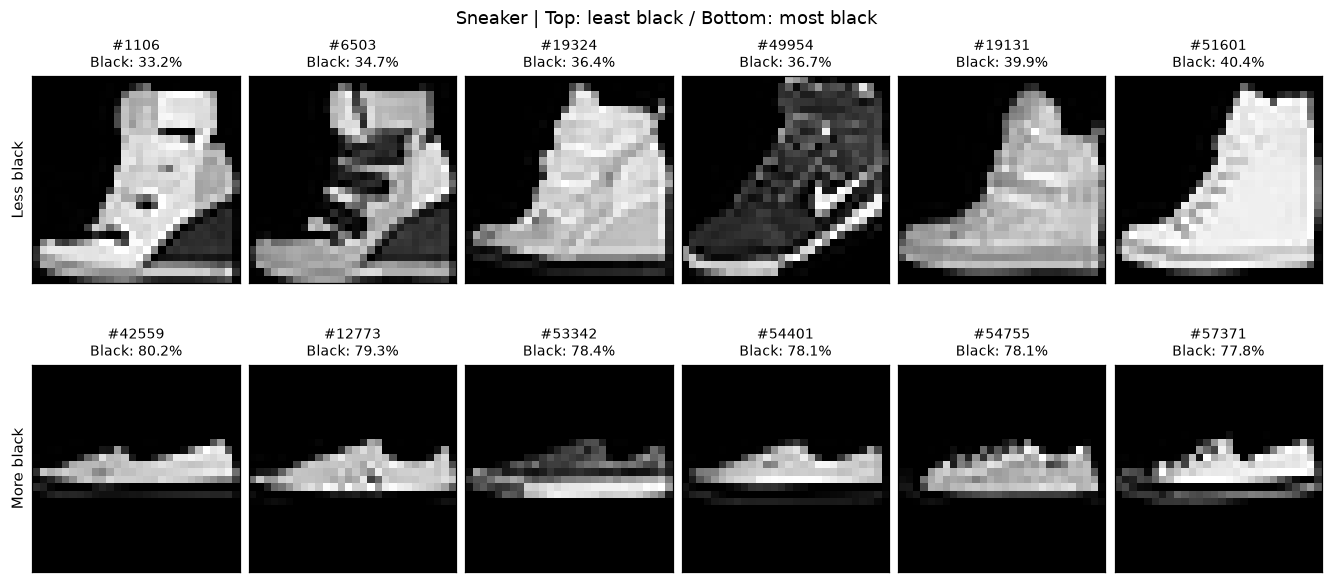

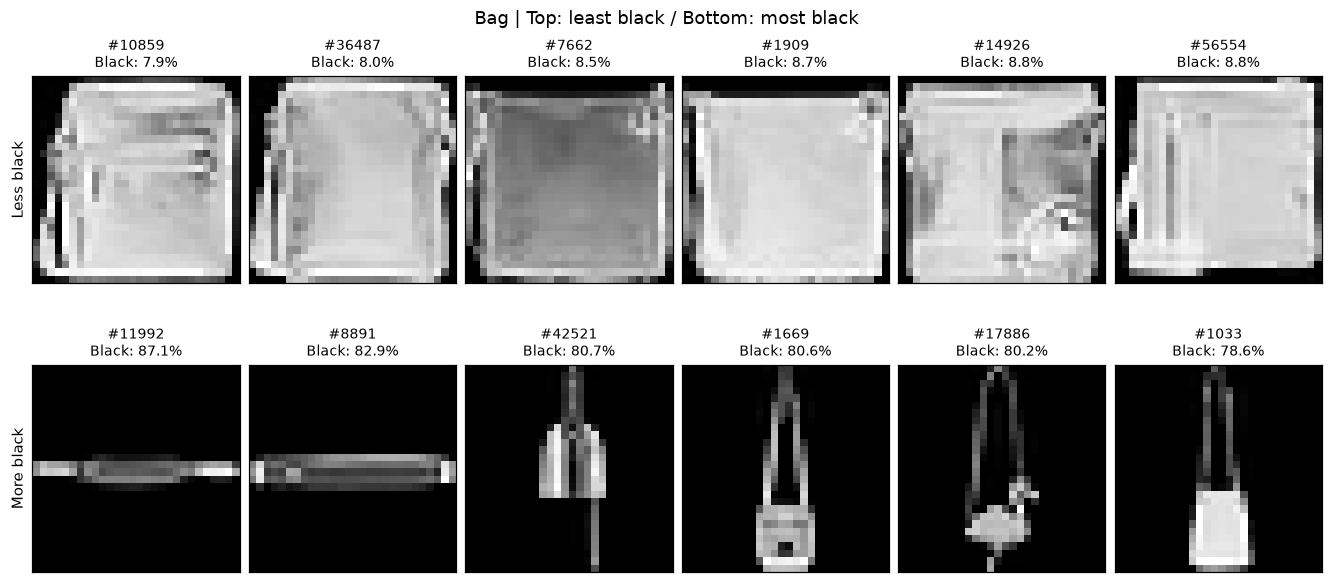

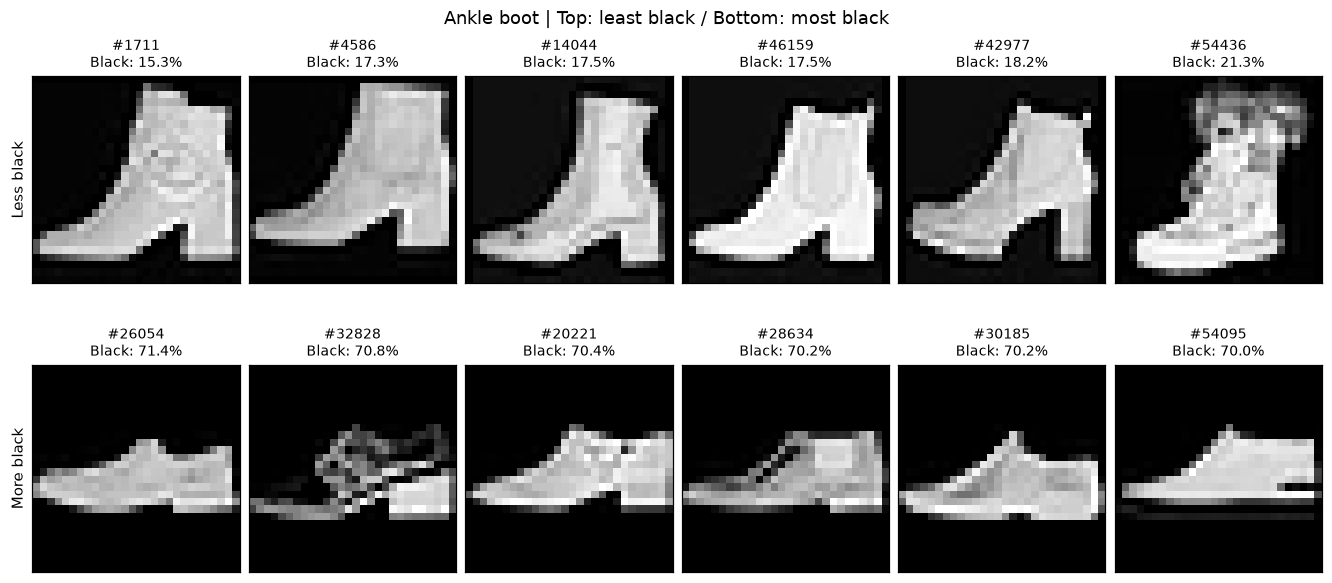

In [9]:
# 이미지마다 784칸 중 완전히 검정인 칸의 비율을 구합니다.
black_pixel_ratios = (train_images == 0).mean(axis=(1, 2))
black_ratio_examples = {}

for label, name in enumerate(class_names):
    class_indices = np.flatnonzero(train_labels == label)
    ratios = black_pixel_ratios[class_indices]

    # 비율이 같을 때는 원본 이미지 번호가 작은 것을 먼저 고릅니다.
    least_black = class_indices[np.argsort(ratios, kind="stable")[:6]]
    most_black = class_indices[np.argsort(-ratios, kind="stable")[:6]]
    black_ratio_examples[label] = {"least": least_black, "most": most_black}

    fig, axes = plt.subplots(2, 6, figsize=(12, 5.5), layout="constrained")
    for row, chosen in enumerate([least_black, most_black]):
        for column, index in enumerate(chosen):
            ax = axes[row, column]
            ax.imshow(train_images[index], cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"#{index}\nBlack: {black_pixel_ratios[index]:.1%}", fontsize=9)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[row, 0].set_ylabel("Less black" if row == 0 else "More black", fontsize=10)

    fig.suptitle(f"{name} | Top: least black / Bottom: most black", fontsize=12)
    plt.show()

#### 3.5.4. 클래스 평균보다 어두운 이미지와 밝은 이미지

**정렬 기준:** 이미지 한 장의 **평균 밝기**

| 위치 | 클래스별 출력 |
| --- | --- |
| **윗줄** | 클래스 평균보다 **어두운 쪽 6장** — 가장 어두운 순 |
| **아랫줄** | 클래스 평균보다 **밝은 쪽 6장** — 가장 밝은 순 |

- **`Mean`:** 이미지의 평균 밝기
- **`z`:** 클래스 평균에서 몇 표준편차 떨어졌는지. **음수는 어두운 쪽, 양수는 밝은 쪽**

> 여기서는 **이미지별 평균 밝기들의 표준편차**를 사용합니다. 3.5.2의 위치별 표준편차와 다르며, 배경도 포함합니다.

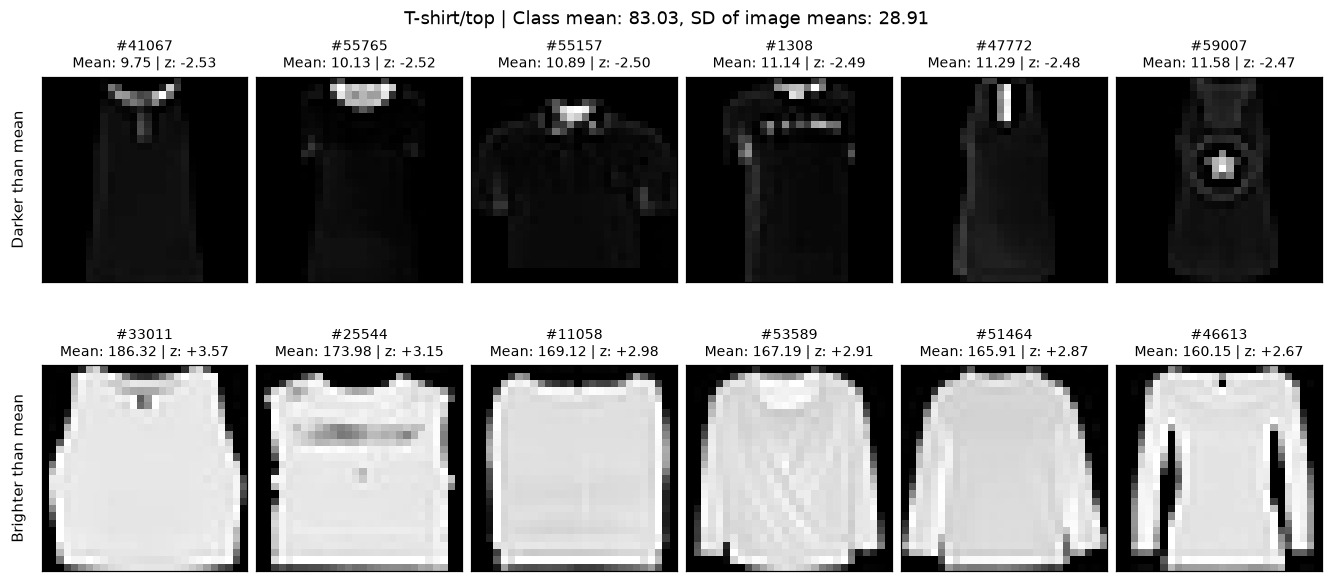

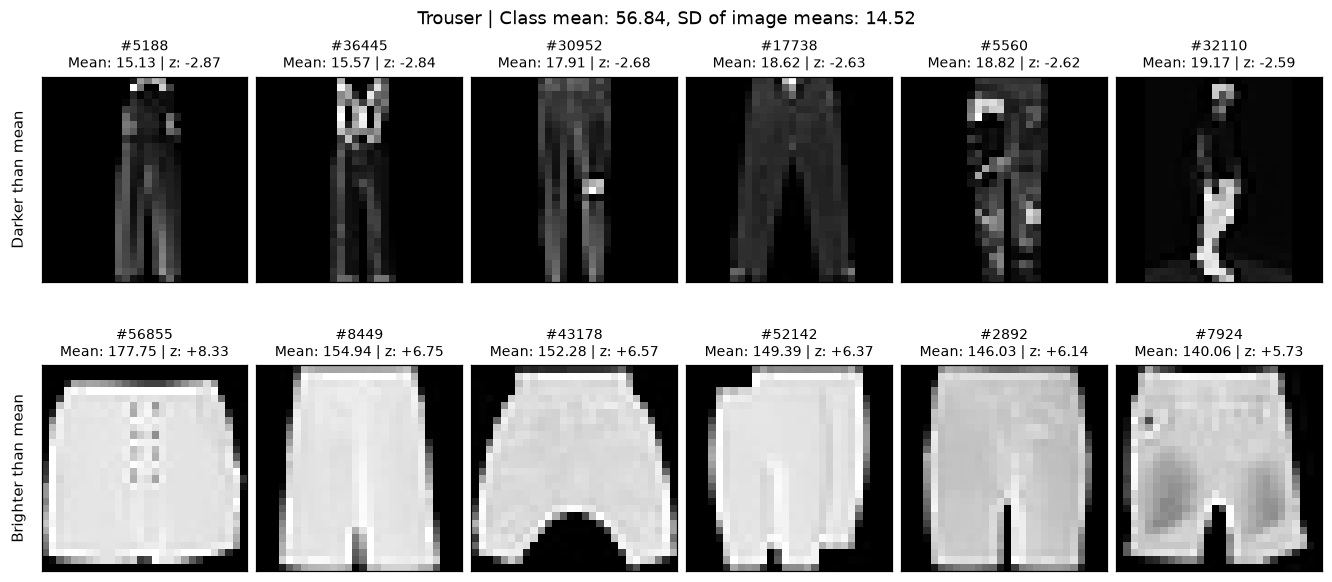

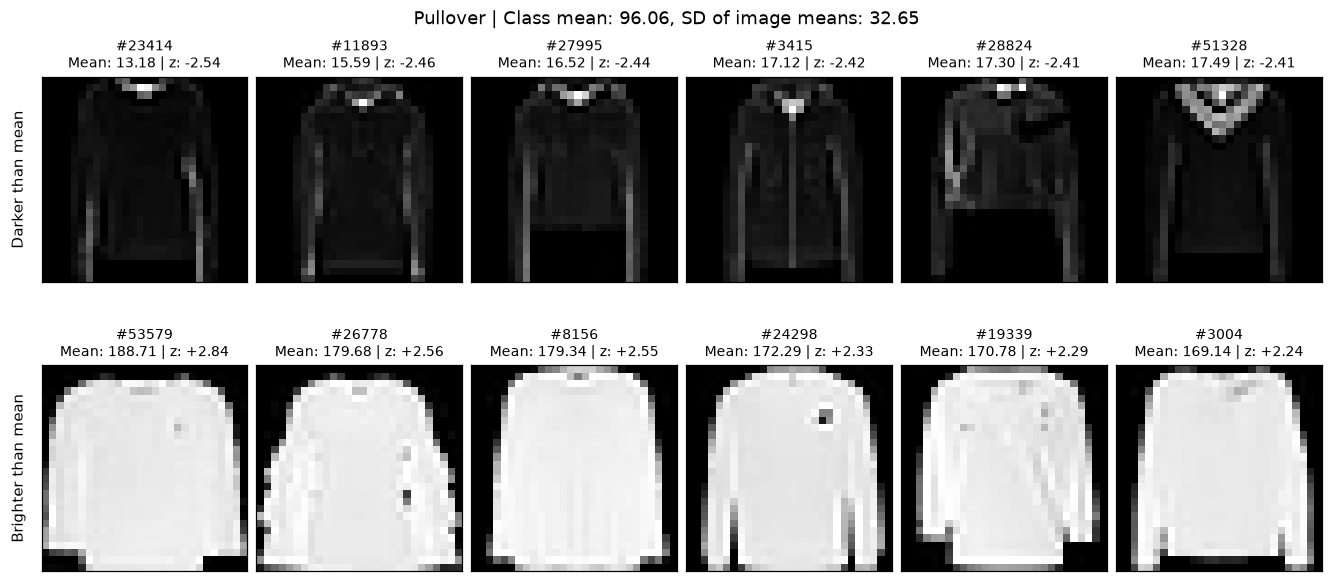

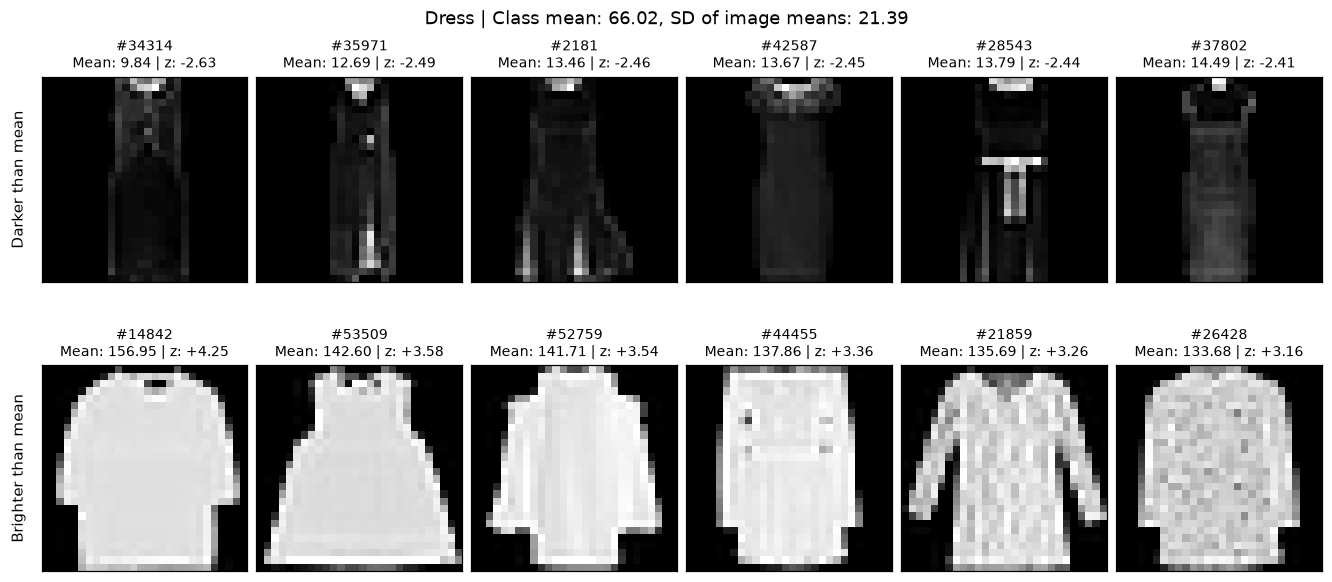

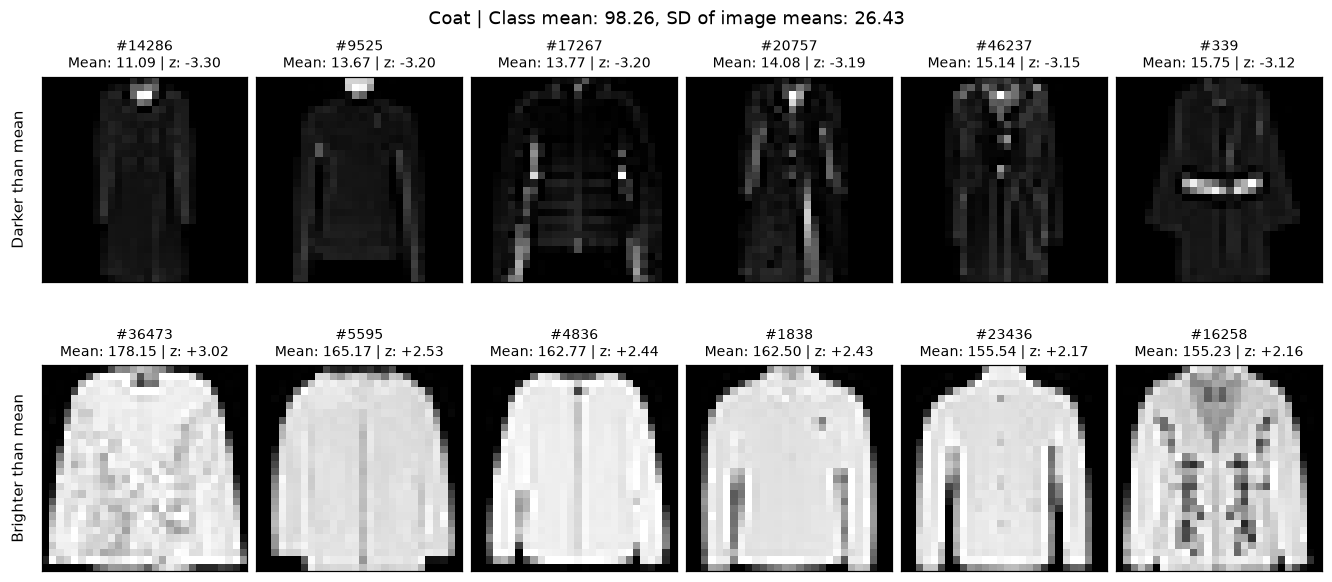

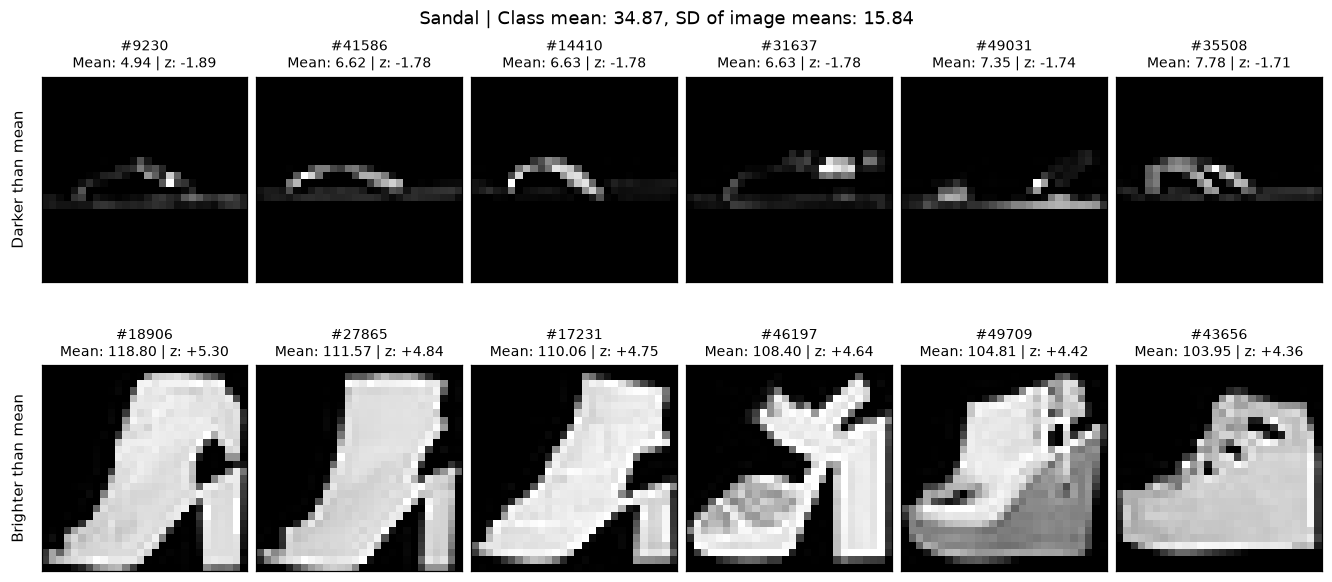

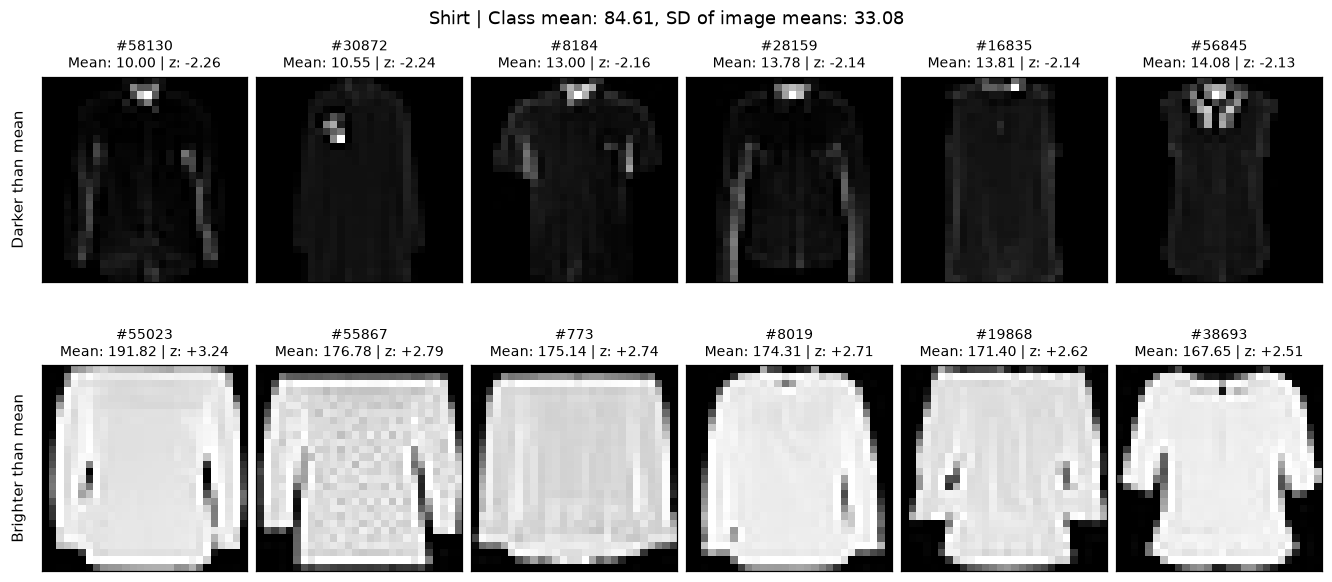

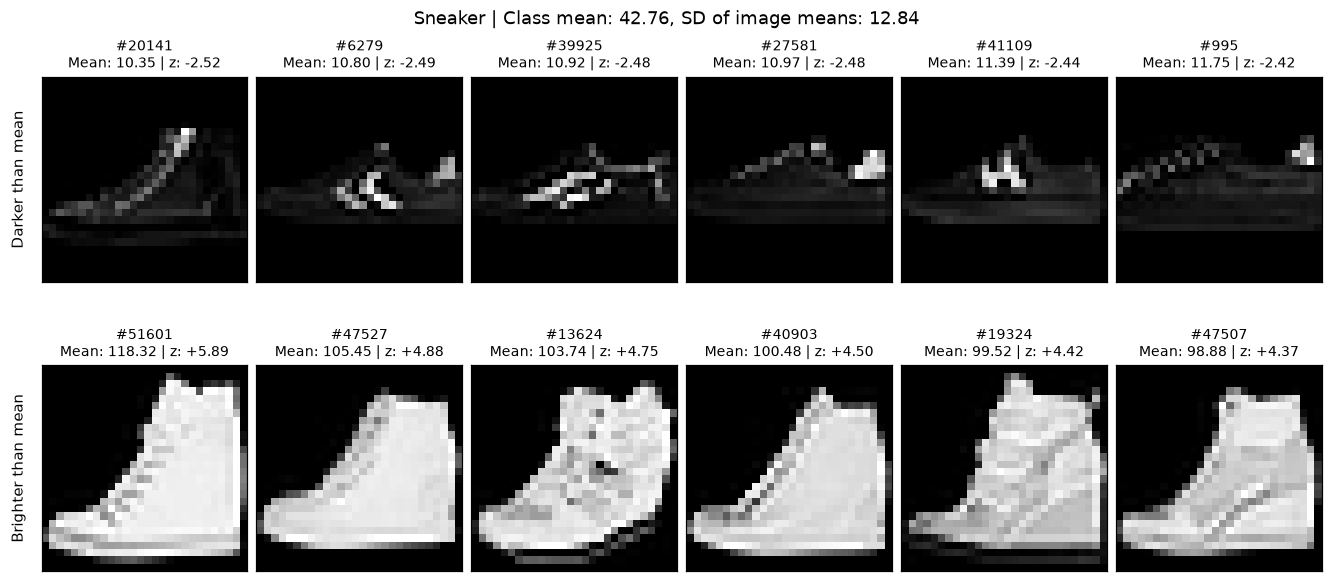

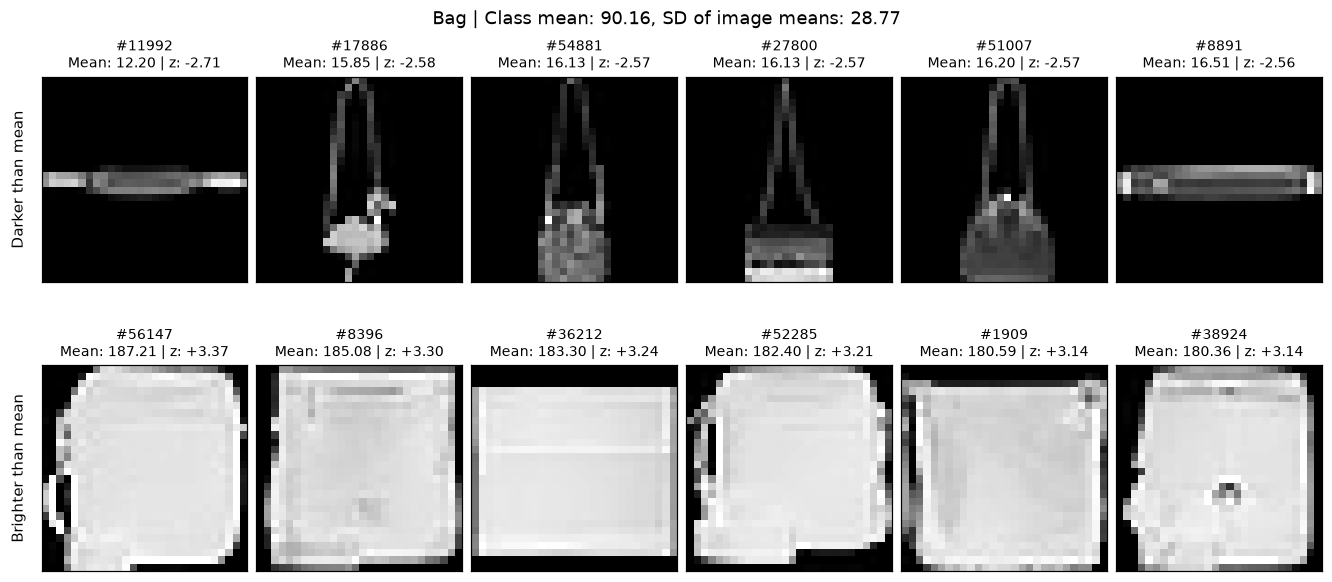

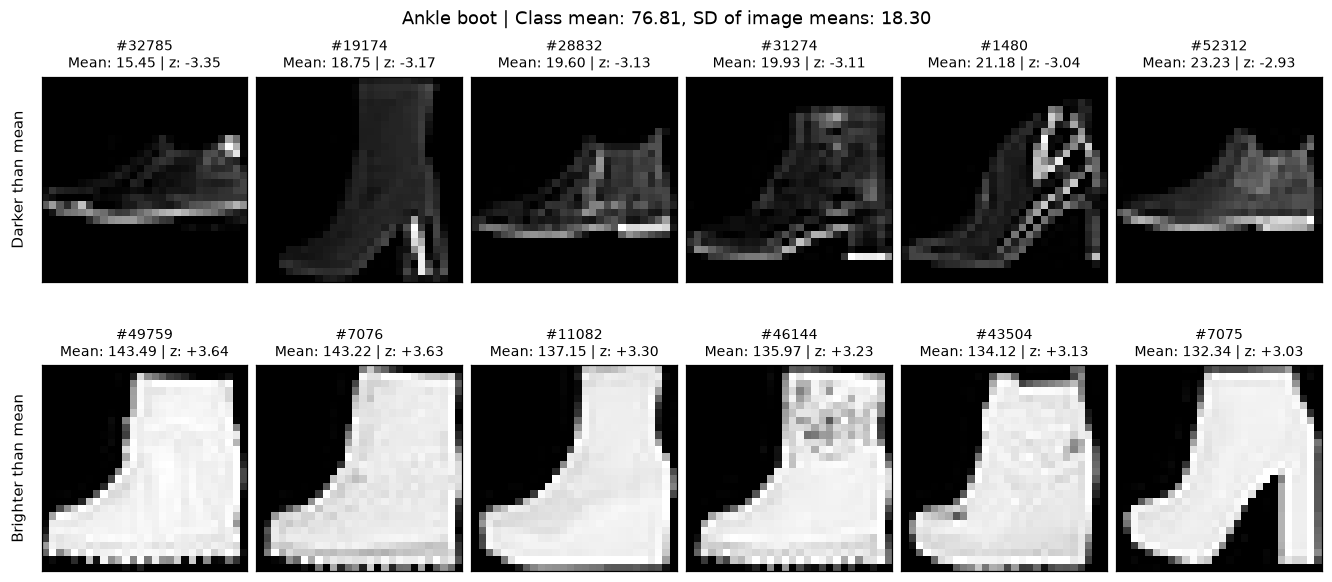

In [10]:
# 이미지 한 장마다 원본 픽셀값 784개의 평균 밝기를 구합니다.
image_mean_brightness = train_images.mean(axis=(1, 2))
brightness_examples = {}
brightness_statistics = []

for label, name in enumerate(class_names):
    class_indices = np.flatnonzero(train_labels == label)
    class_brightness = image_mean_brightness[class_indices]
    class_mean = float(class_brightness.mean())
    class_std = float(class_brightness.std(ddof=0))
    brightness_statistics.append({"클래스": name, "평균 밝기의 평균": class_mean,
                                  "평균 밝기의 표준편차": class_std})

    darker = class_indices[class_brightness < class_mean]
    brighter = class_indices[class_brightness > class_mean]
    darkest_six = darker[np.argsort(image_mean_brightness[darker], kind="stable")[:6]]
    brightest_six = brighter[np.argsort(-image_mean_brightness[brighter], kind="stable")[:6]]
    brightness_examples[label] = {"dark": darkest_six, "bright": brightest_six}

    fig, axes = plt.subplots(2, 6, figsize=(12, 5.5), layout="constrained")
    for row, chosen in enumerate([darkest_six, brightest_six]):
        for column in range(6):
            ax = axes[row, column]
            ax.set_xticks([])
            ax.set_yticks([])
            if column >= len(chosen):
                ax.text(0.5, 0.5, "No image", ha="center", va="center")
                continue
            index = int(chosen[column])
            mean_value = float(image_mean_brightness[index])
            z_score = (mean_value - class_mean) / class_std if class_std > 0 else 0.0
            ax.imshow(train_images[index], cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"#{index}\nMean: {mean_value:.2f} | z: {z_score:+.2f}", fontsize=9)
        axes[row, 0].set_ylabel("Darker than mean" if row == 0 else "Brighter than mean",
                                fontsize=10, labelpad=10)
    fig.suptitle(f"{name} | Class mean: {class_mean:.2f}, SD of image means: {class_std:.2f}", fontsize=12)
    plt.show()

brightness_statistics = pd.DataFrame(brightness_statistics)

### 3.6. 이상 및 중복 데이터 확인

#### 3.6.1. 완전 동일한 이미지 확인

**판정 기준: 두 이미지의 784개 픽셀값이 전부 일치하는가?**

**비교 구간:** train 내부 / test 내부 / train ↔ test

| 용어 | 뜻 |
| --- | --- |
| **묶음** | 완전히 같은 이미지가 모인 그룹 |
| **쌍** | 같은 이미지 두 장을 짝지은 경우 |

> 단색 이미지와 레이블의 기본 점검 결과도 마지막 요약에 사용합니다.

In [11]:
# 기본 점검 결과는 마지막 EDA 요약에도 사용합니다.
quality_rows = []
for split, (images, labels) in datasets.items():
    flat = images.reshape(len(images), -1)
    minimum, maximum = flat.min(axis=1), flat.max(axis=1)
    quality_rows.append({
        "구분": split,
        "이미지·레이블 개수 일치": len(images) == len(labels),
        "범위를 벗어난 레이블 수": int(((labels < 0) | (labels >= num_classes)).sum()),
        "모든 픽셀이 같은 이미지 수": int((minimum == maximum).sum()),
        "전체가 검정인 이미지 수": int((maximum == 0).sum()),
        "전체가 흰색인 이미지 수": int((minimum == 255).sum()),
    })
quality_summary = pd.DataFrame(quality_rows)

# 클래스에 관계없이 train·test의 모든 원본 픽셀을 그대로 비교합니다.
image_groups = {}
for split, (images, labels) in datasets.items():
    for index, (image, label) in enumerate(zip(images, labels)):
        image_groups.setdefault(image.tobytes(), []).append((split, index, int(label)))
duplicate_groups = [group for group in image_groups.values() if len(group) > 1]
cross_split_groups = [group for group in duplicate_groups if len({item[0] for item in group}) == 2]
conflicting_groups = [group for group in duplicate_groups if len({item[2] for item in group}) > 1]

exact_rows, duplicate_rows = [], []
for split in datasets:
    counts = [sum(item[0] == split for item in group) for group in duplicate_groups]
    duplicated_counts = [count for count in counts if count >= 2]
    exact_rows.append({
        "비교 구간": f"{split} 내부",
        "동일 이미지 묶음 수": len(duplicated_counts),
        "동일 이미지 쌍 수": sum(count * (count - 1) // 2 for count in duplicated_counts),
        "해당 train 이미지 수": sum(duplicated_counts) if split == "train" else 0,
        "해당 test 이미지 수": sum(duplicated_counts) if split == "test" else 0,
    })
    duplicate_rows.append({"구분": split, "내부 중복 묶음 수": len(duplicated_counts),
                           "추가 중복 장수": sum(count - 1 for count in duplicated_counts)})

cross_train_counts = [sum(item[0] == "train" for item in group) for group in cross_split_groups]
cross_test_counts = [sum(item[0] == "test" for item in group) for group in cross_split_groups]
exact_rows.append({
    "비교 구간": "train ↔ test",
    "동일 이미지 묶음 수": len(cross_split_groups),
    "동일 이미지 쌍 수": sum(a * b for a, b in zip(cross_train_counts, cross_test_counts)),
    "해당 train 이미지 수": sum(cross_train_counts),
    "해당 test 이미지 수": sum(cross_test_counts),
})
exact_summary = pd.DataFrame(exact_rows)
duplicate_summary = pd.DataFrame(duplicate_rows)
display(exact_summary)
print(f"동일 이미지의 레이블 불일치: {len(conflicting_groups):,}묶음")

# 중복이 있으면 최대 5묶음의 사례를 나란히 보여줍니다.
if duplicate_groups:
    examples = duplicate_groups[:5]
    fig, axes = plt.subplots(len(examples), 2, figsize=(6, 2.6 * len(examples)), squeeze=False,
                             layout="constrained")
    for row, group in enumerate(examples):
        for column, (split, index, label) in enumerate(group[:2]):
            axes[row, column].imshow(datasets[split][0][index], cmap="gray", vmin=0, vmax=255)
            axes[row, column].set_title(f"{split}[{index}] | {class_names[label]}")
            axes[row, column].axis("off")
    plt.show()
else:
    print("세 비교 구간 모두에서 완전히 동일한 이미지를 찾지 못했습니다.")
del image_groups

,비교 구간,동일 이미지 묶음 수,동일 이미지 쌍 수,해당 train 이미지 수,해당 test 이미지 수
0,train 내부,0,0,0,0
1,test 내부,0,0,0,0
2,train ↔ test,0,0,0,0


동일 이미지의 레이블 불일치: 0묶음
세 비교 구간 모두에서 완전히 동일한 이미지를 찾지 못했습니다.


#### 3.6.2. 유사 이미지 확인 — 코사인 유사도(초기 탐색)

**찾는 것:** 픽셀 밝기의 **배치 패턴**이 비슷한 이미지

| 항목 | 설정 |
| --- | --- |
| 비교 범위 | 클래스 구분 없이 train·test 전체 |
| 후보 기준 | 코사인 유사도 **0.99 이상** — 1에 가까울수록 비슷함 |
| 집계 단위 | 기준을 만족하는 **모든 이미지 쌍** |
| 출력 순서 | 유사도가 **높은 순 12쌍** |
| 이미지 배치 | **윗줄 train / 아랫줄 test**, 같은 열이 한 쌍 |

> 전체 밝기가 같은 비율로 바뀌어도 높은 값이 나올 수 있습니다. **초기 탐색 기록**으로 남깁니다.

,유사도 기준,유사 후보 쌍 수,해당 train 이미지 수,해당 test 이미지 수,클래스가 다른 후보 쌍 수
0,0.99,1398,1026,545,46


전체 train·test 비교: 600,000,000쌍
유사도 0.99 이상: 1,398쌍


,후보_쌍_수,train_이미지_수,test_이미지_수,최고_유사도
test_class,,,,
T-shirt/top,245,187,102,0.999974
Trouser,478,322,171,0.999617
Pullover,303,233,98,0.997482
Dress,22,22,20,0.996683
Coat,189,146,84,0.999880
Sandal,0,0,0,NaN
Shirt,144,109,57,0.999923
Sneaker,0,0,0,NaN
Bag,11,11,8,0.998401


,train_index,train_class,test_index,test_class,similarity
0,13360,T-shirt/top,4998,T-shirt/top,0.999974
1,11932,Shirt,2605,Shirt,0.999923
2,6300,Coat,6210,Coat,0.999880
3,58762,T-shirt/top,9867,T-shirt/top,0.999839
4,51488,Shirt,2605,Shirt,0.999779
5,19456,Coat,6210,Coat,0.999764
6,20255,Shirt,4222,Shirt,0.999742
7,18494,Trouser,2115,Trouser,0.999617
8,59025,Trouser,2115,Trouser,0.999512
9,18494,Trouser,4926,Trouser,0.999361


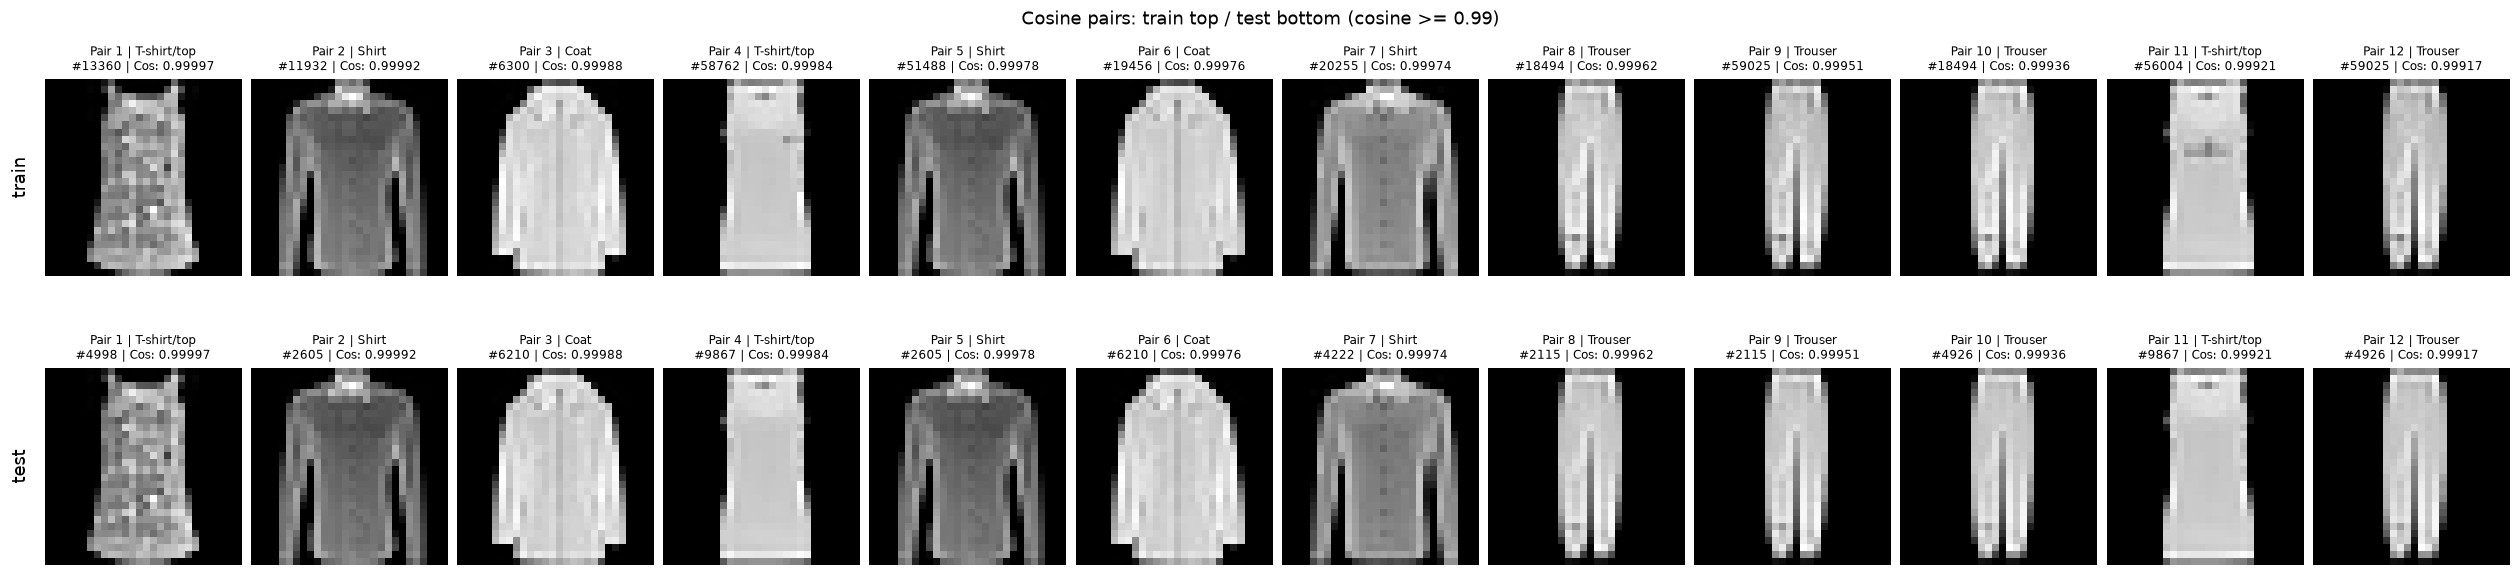

In [12]:
SIMILARITY_THRESHOLD = 0.99
MAX_PAIRS_TO_SHOW = 12
SIMILARITY_BATCH_SIZE = 128

# 28×28 원본 픽셀을 사용하고 밝기 배치의 코사인 유사도를 계산합니다.
train_features = torch.from_numpy(train_images.reshape(len(train_images), -1)).float()
test_features = torch.from_numpy(test_images.reshape(len(test_images), -1)).float()
train_features = torch.nn.functional.normalize(train_features, dim=1)
test_features = torch.nn.functional.normalize(test_features, dim=1)
train_pair_parts, test_pair_parts, score_parts = [], [], []

with torch.no_grad():
    for start in range(0, len(test_images), SIMILARITY_BATCH_SIZE):
        # 전체 10,000×60,000 행렬을 한 번에 저장하지 않고 나눠 계산합니다.
        scores = (test_features[start:start + SIMILARITY_BATCH_SIZE] @ train_features.T).clamp_(0, 1)
        test_positions, train_positions = torch.where(scores >= SIMILARITY_THRESHOLD)
        if len(test_positions):
            train_pair_parts.append(train_positions.numpy())
            test_pair_parts.append((test_positions + start).numpy())
            score_parts.append(scores[test_positions, train_positions].numpy())

if score_parts:
    cosine_pairs = pd.DataFrame({
        "train_index": np.concatenate(train_pair_parts),
        "test_index": np.concatenate(test_pair_parts),
        "similarity": np.concatenate(score_parts),
    })
    cosine_pairs["train_class"] = [class_names[label] for label in train_labels[cosine_pairs["train_index"]]]
    cosine_pairs["test_class"] = [class_names[label] for label in test_labels[cosine_pairs["test_index"]]]
    cosine_pairs = cosine_pairs.sort_values("similarity", ascending=False, kind="stable").reset_index(drop=True)
else:
    cosine_pairs = pd.DataFrame(columns=["train_index", "test_index", "similarity", "train_class", "test_class"])

del train_features, test_features, scores, train_pair_parts, test_pair_parts, score_parts
cosine_summary = pd.DataFrame([{
    "유사도 기준": SIMILARITY_THRESHOLD,
    "유사 후보 쌍 수": len(cosine_pairs),
    "해당 train 이미지 수": cosine_pairs["train_index"].nunique(),
    "해당 test 이미지 수": cosine_pairs["test_index"].nunique(),
    "클래스가 다른 후보 쌍 수": int((cosine_pairs["train_class"] != cosine_pairs["test_class"]).sum()),
}])
display(cosine_summary)
print(f"전체 train·test 비교: {len(train_images) * len(test_images):,}쌍")
print(f"유사도 {SIMILARITY_THRESHOLD:.2f} 이상: {len(cosine_pairs):,}쌍")

if len(cosine_pairs):
    # test의 클래스별로 후보 쌍 수와 서로 다른 이미지 수를 정리합니다.
    cosine_class_summary = (cosine_pairs.groupby("test_class", sort=False)
        .agg(후보_쌍_수=("similarity", "size"), train_이미지_수=("train_index", "nunique"),
             test_이미지_수=("test_index", "nunique"), 최고_유사도=("similarity", "max"))
        .reindex(class_names))
    cosine_class_summary[["후보_쌍_수", "train_이미지_수", "test_이미지_수"]] = cosine_class_summary[["후보_쌍_수", "train_이미지_수", "test_이미지_수"]].fillna(0).astype(int)
    display(cosine_class_summary.round(6))
    cosine_shown_pairs = cosine_pairs.head(MAX_PAIRS_TO_SHOW)
    display(cosine_shown_pairs[["train_index", "train_class", "test_index", "test_class", "similarity"]].round(6))

    # 같은 열이 한 쌍입니다. 윗줄은 train, 아랫줄은 test입니다.
    pair_count = len(cosine_shown_pairs)
    fig, axes = plt.subplots(2, pair_count, figsize=(max(7, 1.9 * pair_count), 5.5),
                             squeeze=False, layout="constrained")
    for column, (_, row) in enumerate(cosine_shown_pairs.iterrows()):
        train_index, test_index = int(row["train_index"]), int(row["test_index"])
        for plot_row, (index, image, name) in enumerate([
            (train_index, train_images[train_index], row["train_class"]),
            (test_index, test_images[test_index], row["test_class"]),
        ]):
            ax = axes[plot_row, column]
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"Pair {column + 1} | {name}\n#{index} | Cos: {row['similarity']:.5f}", fontsize=8)
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
    axes[0, 0].set_ylabel("train", fontsize=12, labelpad=10)
    axes[1, 0].set_ylabel("test", fontsize=12, labelpad=10)
    fig.suptitle(f"Cosine pairs: train top / test bottom (cosine >= {SIMILARITY_THRESHOLD})", fontsize=12)
    plt.show()
else:
    print("설정한 기준 이상의 유사 후보가 없습니다.")

**유클리드 거리로 진행한 이유**

- **처음:** 밝기 배치가 비슷한 이미지를 넓게 찾기 → **코사인**
- **최종 목적:** train·test에 **실제 픽셀값이 거의 같은 이미지**가 있는지 확인 → **유클리드**

| 구분 | 코사인 — 초기 탐색 | 유클리드 — 최종 검사 |
| --- | --- | --- |
| 비교하는 것 | 밝기 배치 패턴 | 실제 픽셀값 차이 |
| 비교 범위 | 클래스 구분 없는 전체 비교 | 같은 클래스끼리 비교 |
| 후보 기준 | 유사도 **0.99 이상** | 0~1 픽셀값에서 거리 **1.0 미만** |
| 집계 단위 | 모든 후보 **쌍** | 최근접 거리가 기준 미만인 **test 이미지** |

> **1,398쌍과 16장은 직접 비교할 수 없습니다.** 비교 범위·집계 단위도 다릅니다. 기준값은 조절 가능하며, 유사성만으로 데이터 누수를 확정하지 않습니다.

#### 3.6.3. 유사 이미지 확인 — 유클리드 거리(최종 검사)

**찾는 것:** 실제 픽셀값 차이가 작은 이미지. **거리 0은 완전 동일**, 작을수록 비슷합니다.

| 항목 | 설정 |
| --- | --- |
| 픽셀값 범위 | 원본을 **0~1**로 변환 |
| 비교 방식 | test마다 **같은 클래스의 train 전체**에서 가장 가까운 한 장 선택 |
| 후보 기준 | 거리 **1.0 미만** — `NEAR_DUPLICATE_DISTANCE`에서 조절 |
| 집계 단위 | 기준을 만족하는 **test 이미지 수** |
| 출력 순서 | 클래스별로 나누지 않고, 최근접 쌍 전체에서 **거리가 작은 순 12쌍** |
| 이미지 배치 | **윗줄 train / 아랫줄 test**, 같은 열이 한 쌍 |

**그림 표시:** `candidate`는 기준 미만 / `reference`는 기준 밖의 비교용 사례

> 모든 유사 쌍을 센 결과는 아닙니다. **작은 거리만으로 데이터 누수를 확정하지 않습니다.**

T-shirt/top: train 6,000장과 test 1,000장 비교 완료
Trouser: train 6,000장과 test 1,000장 비교 완료
Pullover: train 6,000장과 test 1,000장 비교 완료
Dress: train 6,000장과 test 1,000장 비교 완료
Coat: train 6,000장과 test 1,000장 비교 완료
Sandal: train 6,000장과 test 1,000장 비교 완료
Shirt: train 6,000장과 test 1,000장 비교 완료
Sneaker: train 6,000장과 test 1,000장 비교 완료
Bag: train 6,000장과 test 1,000장 비교 완료
Ankle boot: train 6,000장과 test 1,000장 비교 완료


,거리 기준(미만),유사 후보 test 이미지 수,test 전체 대비 비율(%),대응하는 서로 다른 train 이미지 수,최근접 거리 중앙값
0,1.0,16,0.16,15,3.5219


,클래스,test 이미지 수,유사 후보 test 이미지 수,후보 비율(%),대응 train 이미지 수,최소 거리,거리 중앙값
0,T-shirt/top,1000,2,0.2,2,0.0816,3.2987
1,Trouser,1000,6,0.6,5,0.3914,2.2508
2,Pullover,1000,0,0.0,0,1.3128,3.4783
3,Dress,1000,1,0.1,1,0.7110,3.4223
4,Coat,1000,1,0.1,1,0.3729,3.5303
5,Sandal,1000,0,0.0,0,1.1291,4.2253
6,Shirt,1000,6,0.6,6,0.3028,3.6504
7,Sneaker,1000,0,0.0,0,1.4954,3.0371
8,Bag,1000,0,0.0,0,1.2721,4.6137
9,Ankle boot,1000,0,0.0,0,1.7613,3.7092


거리 1.00 미만인 test 이미지: 16장
대응하는 서로 다른 train 이미지: 15장


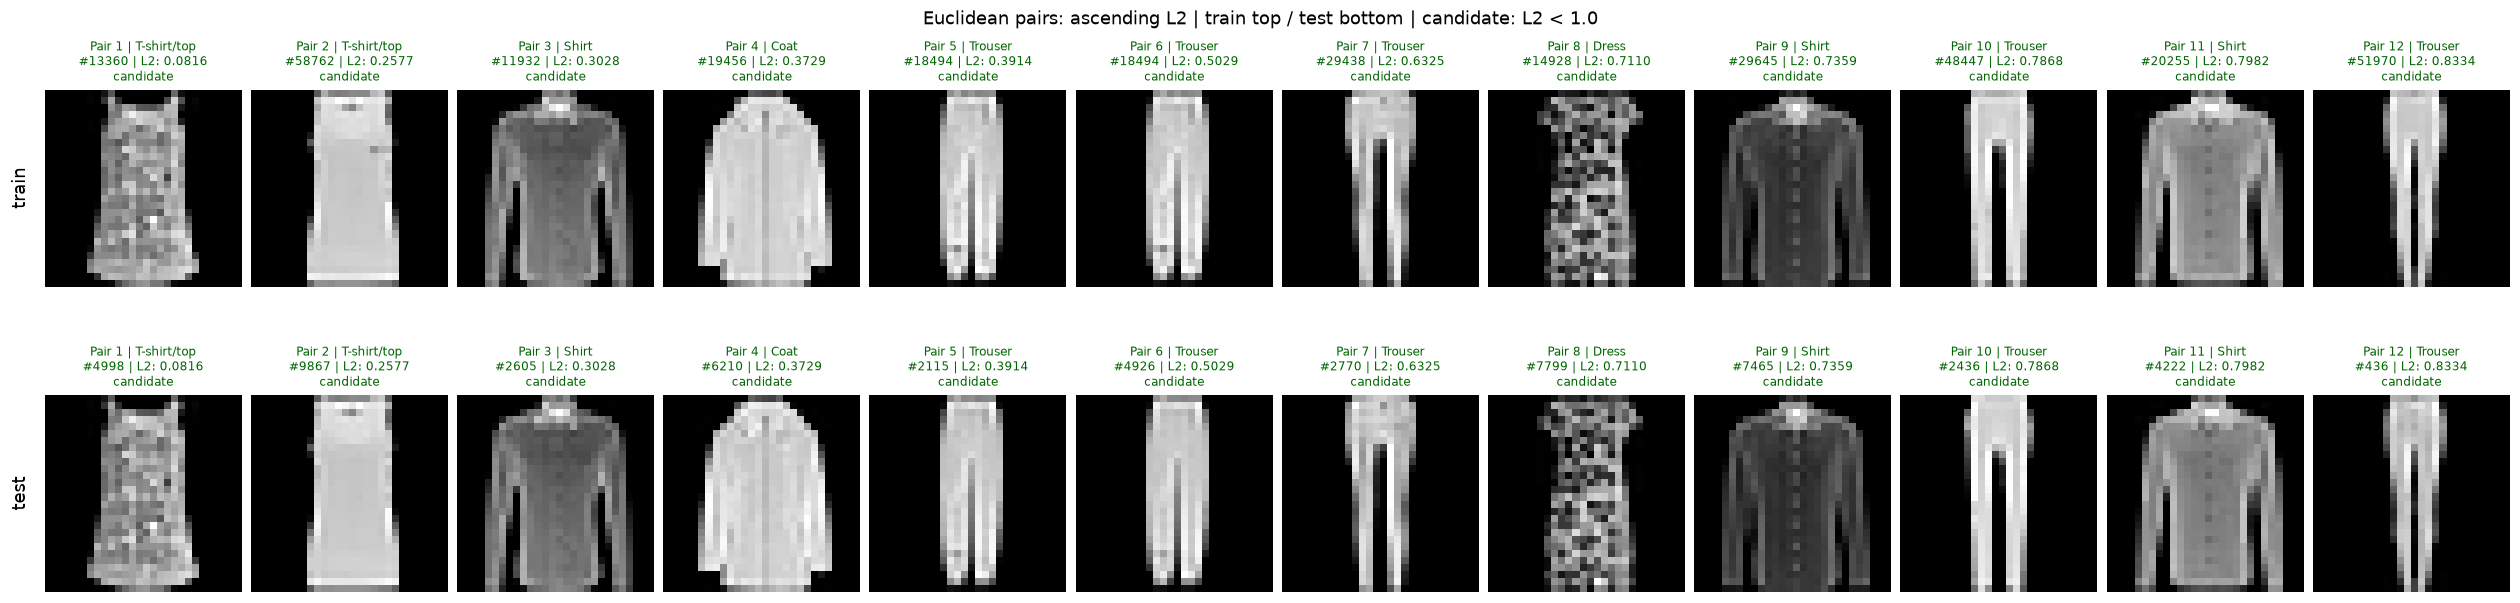

In [3]:
NEAR_DUPLICATE_DISTANCE = 1.0
MAX_EUCLIDEAN_PAIRS_TO_SHOW = 12
DISTANCE_BATCH_SIZE = 256
comparison_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
nearest_rows = []

with torch.no_grad():
    for label, name in enumerate(class_names):
        train_indices = np.flatnonzero(train_labels == label)
        test_indices = np.flatnonzero(test_labels == label)
        # GAN 입력의 -1~1 정규화와 별도로, 거리 계산에는 원본을 0~1로 맞춥니다.
        train_vectors = torch.from_numpy(train_images[train_indices]).to(comparison_device, dtype=torch.float32).div(255).flatten(1)
        test_vectors = torch.from_numpy(test_images[test_indices]).to(comparison_device, dtype=torch.float32).div(255).flatten(1)
        nearest_indices = []
        for start in range(0, len(test_indices), DISTANCE_BATCH_SIZE):
            distances = torch.cdist(test_vectors[start:start + DISTANCE_BATCH_SIZE], train_vectors, p=2)
            nearest_indices.append(distances.argmin(dim=1).cpu().numpy())
        matched_train = train_indices[np.concatenate(nearest_indices)]

        # 선택된 두 원본의 차이로 거리를 다시 계산해 반올림 오차를 줄입니다.
        pixel_difference = (test_images[test_indices].astype(np.float64)
                            - train_images[matched_train].astype(np.float64)) / 255.0
        exact_distances = np.linalg.norm(pixel_difference.reshape(len(test_indices), -1), axis=1)
        for test_index, train_index, distance in zip(test_indices, matched_train, exact_distances):
            nearest_rows.append({"class": name, "label": label,
                                 "train_index": int(train_index), "test_index": int(test_index),
                                 "distance": float(distance)})
        print(f"{name}: train {len(train_indices):,}장과 test {len(test_indices):,}장 비교 완료")

del train_vectors, test_vectors, distances, pixel_difference
nearest_matches = pd.DataFrame(nearest_rows)
nearest_matches["is_candidate"] = nearest_matches["distance"] < NEAR_DUPLICATE_DISTANCE
similar_pairs = nearest_matches[nearest_matches["is_candidate"]].sort_values("distance", kind="stable").reset_index(drop=True)

distance_summary = pd.DataFrame([{
    "거리 기준(미만)": NEAR_DUPLICATE_DISTANCE,
    "유사 후보 test 이미지 수": len(similar_pairs),
    "test 전체 대비 비율(%)": len(similar_pairs) / len(test_images) * 100,
    "대응하는 서로 다른 train 이미지 수": similar_pairs["train_index"].nunique(),
    "최근접 거리 중앙값": nearest_matches["distance"].median(),
}])
display(distance_summary.round(4))

class_distance_rows = []
for name in class_names:
    matches = nearest_matches[nearest_matches["class"] == name]
    candidates = matches[matches["is_candidate"]]
    class_distance_rows.append({
        "클래스": name, "test 이미지 수": len(matches),
        "유사 후보 test 이미지 수": len(candidates),
        "후보 비율(%)": len(candidates) / len(matches) * 100,
        "대응 train 이미지 수": candidates["train_index"].nunique(),
        "최소 거리": matches["distance"].min(), "거리 중앙값": matches["distance"].median(),
    })
class_distance_summary = pd.DataFrame(class_distance_rows)
display(class_distance_summary.round(4))
print(f"거리 {NEAR_DUPLICATE_DISTANCE:.2f} 미만인 test 이미지: {len(similar_pairs):,}장")
print(f"대응하는 서로 다른 train 이미지: {similar_pairs['train_index'].nunique():,}장")

# 클래스별로 그림을 나누지 않고, 최근접 쌍 전체를 거리 오름차순으로 나열합니다.
shown_pairs = (nearest_matches.sort_values("distance", ascending=True, kind="stable")
               .head(MAX_EUCLIDEAN_PAIRS_TO_SHOW).reset_index(drop=True))
pair_count = len(shown_pairs)
fig, axes = plt.subplots(2, pair_count, figsize=(max(7, 1.9 * pair_count), 5.8),
                         squeeze=False, layout="constrained")
for column, row in shown_pairs.iterrows():
    train_index, test_index = int(row["train_index"]), int(row["test_index"])
    status = "candidate" if row["is_candidate"] else "reference (outside threshold)"
    for plot_row, (index, image) in enumerate([
        (train_index, train_images[train_index]),
        (test_index, test_images[test_index]),
    ]):
        ax = axes[plot_row, column]
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"Pair {column + 1} | {row['class']}\n#{index} | L2: {row['distance']:.4f}\n{status}", fontsize=8,
                     color="darkgreen" if row["is_candidate"] else "dimgray")
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
axes[0, 0].set_ylabel("train", fontsize=12, labelpad=10)
axes[1, 0].set_ylabel("test", fontsize=12, labelpad=10)
fig.suptitle(f"Euclidean pairs: ascending L2 | train top / test bottom | candidate: L2 < {NEAR_DUPLICATE_DISTANCE}", fontsize=12)
plt.show()

### 3.7. EDA 결과 정리

**앞서 계산한 결과를 한곳에 모읍니다.**

데이터 구조 · 클래스 분포 · 픽셀 특징 · 이상 및 중복 데이터

In [14]:
print("[데이터 구조]")
for split, (images, labels) in datasets.items():
    print(f"- {split}: 이미지 {len(images):,}장, 한 장 크기 {images.shape[1:]}, 픽셀 범위 {images.min()}~{images.max()}")

print("\n[클래스 분포]")
for split, counts in class_counts.items():
    status = "균등" if counts.min() == counts.max() else "개수 차이 있음"
    print(f"- {split}: {status}, 클래스당 최소 {counts.min():,}장 / 최대 {counts.max():,}장")

brightest = pixel_stats.loc[pixel_stats["평균"].idxmax()]
darkest = pixel_stats.loc[pixel_stats["평균"].idxmin()]
print("\n[픽셀 특징: train]")
print(f"- 평균 밝기가 가장 높은 클래스: {brightest['클래스']} ({brightest['평균']:.2f})")
print(f"- 평균 밝기가 가장 낮은 클래스: {darkest['클래스']} ({darkest['평균']:.2f})")
print("- 위 밝기 계산에는 배경도 포함됩니다.")

print("\n[이상 및 중복 데이터]")
for _, row in quality_summary.iterrows():
    print(f"- {row['구분']}: 전체 픽셀이 같은 이미지 {row['모든 픽셀이 같은 이미지 수']}장, 범위 밖 레이블 {row['범위를 벗어난 레이블 수']}개")
for _, row in duplicate_summary.iterrows():
    print(f"- {row['구분']}: 내부 중복 {row['내부 중복 묶음 수']}묶음, 추가 중복 {row['추가 중복 장수']}장")
print(f"- train·test 공통 이미지: {len(cross_split_groups)}묶음")
print(f"- 동일 이미지의 레이블 불일치: {len(conflicting_groups)}묶음")
print(f"- 초기 코사인 탐색: 클래스 구분 없이 유사도 {SIMILARITY_THRESHOLD:.2f} 이상 {len(cosine_pairs):,}쌍")
print(f"- train·test 유사 후보: 같은 클래스에서 유클리드 거리 {NEAR_DUPLICATE_DISTANCE:.2f} 미만인 test 이미지 {len(similar_pairs):,}장")
print(f"- 후보에 대응하는 서로 다른 train 이미지: {similar_pairs['train_index'].nunique():,}장")
print("- 이 EDA에서는 데이터를 삭제하거나 레이블을 수정하지 않았습니다.")

[데이터 구조]
- train: 이미지 60,000장, 한 장 크기 (28, 28), 픽셀 범위 0~255
- test: 이미지 10,000장, 한 장 크기 (28, 28), 픽셀 범위 0~255

[클래스 분포]
- train: 균등, 클래스당 최소 6,000장 / 최대 6,000장
- test: 균등, 클래스당 최소 1,000장 / 최대 1,000장

[픽셀 특징: train]
- 평균 밝기가 가장 높은 클래스: Coat (98.26)
- 평균 밝기가 가장 낮은 클래스: Sandal (34.87)
- 위 밝기 계산에는 배경도 포함됩니다.

[이상 및 중복 데이터]
- train: 전체 픽셀이 같은 이미지 0장, 범위 밖 레이블 0개
- test: 전체 픽셀이 같은 이미지 0장, 범위 밖 레이블 0개
- train: 내부 중복 0묶음, 추가 중복 0장
- test: 내부 중복 0묶음, 추가 중복 0장
- train·test 공통 이미지: 0묶음
- 동일 이미지의 레이블 불일치: 0묶음
- 초기 코사인 탐색: 클래스 구분 없이 유사도 0.99 이상 1,398쌍
- train·test 유사 후보: 같은 클래스에서 유클리드 거리 1.00 미만인 test 이미지 16장
- 후보에 대응하는 서로 다른 train 이미지: 15장
- 이 EDA에서는 데이터를 삭제하거나 레이블을 수정하지 않았습니다.


### 3.8. EDA 전체 요약

| 목차 | 핵심 결과 |
| --- | --- |
| **3.1. EDA 준비** | 원본 픽셀값 **0~255**를 사용하고 무작위 시드를 고정했습니다. |
| **3.2. 이미지 데이터 구조** | **train 60,000장 / test 10,000장**, 28×28 흑백, 10개 클래스입니다. |
| **3.3. 클래스별 분포** | 클래스마다 **train 6,000장 / test 1,000장**으로 균등합니다. |
| **3.4. 이미지 시각화** | 같은 클래스에서도 모양·무늬·밝기가 다르며, 매우 비슷한 이미지도 관찰됐습니다. |
| **3.5. 픽셀값 분석** | 평균·표준편차 히트맵을 확인했습니다. 검정 비율과 평균 밝기의 양끝 이미지를 **각 6장씩** 비교했습니다. |
| **3.6. 이상·중복 검사** | 완전 동일 **0개**. 초기 코사인 **1,398쌍**, 최종 유클리드 **test 16장 / train 15장**을 확인했습니다. |
| **3.7. 결과 정리** | 단색 이미지와 범위 밖 레이블은 없었습니다. 유사 후보만으로 **데이터 누수 확정은 어렵습니다.** |